<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 4: Data Preparation

This notebook follows `03_EDA.ipynb`. We take the 159-column `merged_data.csv` and cut it down to a smaller, cleaner set of candidate characteristics for grouping, WOE/IV screening and logistic regression. We follow the data-preparation steps from the **Week 9 Lab**: invalid outliers, correlation above 0.8, and ratio features.

**How this notebook is organised**

| Part | What we do |
|---|---|
| **A - Analysis** (4.1-4.9) | We look at every possible removal, missing-value treatment, invalid-value rule, outlier decision and new feature, with the evidence for each |
| **B - Applying our decisions** (4.10-4.11) | We apply the decisions we agreed as a team and export `data/prepared_data.csv` |

In Part A we do not change any data; we only calculate the evidence. Nothing in Part A uses `TARGET`. We make **no train/test split** here; that happens in Step 5 (grouping and WOE/IV screening).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 140)
pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams['figure.dpi'] = 80

## 4.1 Business Context and Data Overview

Our scorecard estimates the probability of default for Home Improvement Loan applicants. It can only be as good as its inputs, so before grouping and WOE/IV screening our candidate characteristics need to be:

- **relevant** to repayment ability or credit risk (capacity to repay, income and job stability, existing debt, repayment behaviour, arrears, credit history)
- **valid**, with no impossible values or special codes pretending to be numbers
- **properly treated** for missing and extreme values
- **not redundant**, so the logistic regression coefficients stay stable (Week 9)
- **few enough** to look at one by one: we aim for about 20-35 candidates, and later pick 8-15 for the scorecard

Segmentation (Step 0), bureau flattening (Step 1), the merge and feature engineering (Step 2) and EDA (Step 3) are done.

We load the source data once into `merged_orig` and **never change it**. Part A only reads it, and Part B works on a separate copy. We store a fingerprint so we can prove this at the end.

In [2]:
merged_path = 'data/merged_data.csv'
if not os.path.exists(merged_path):
    raise FileNotFoundError(f'{merged_path} not found. Run 02_merged_data.ipynb first.')

merged_orig = pd.read_csv(merged_path)
original_fingerprint = pd.util.hash_pandas_object(merged_orig, index=True).sum()

id_col, target_col = 'SK_ID_CURR', 'TARGET'
predictors = [c for c in merged_orig.columns if c not in (id_col, target_col)]

overview = pd.DataFrame({'Result': [
    f'{len(merged_orig):,}',
    merged_orig.shape[1],
    len(predictors),
    merged_orig[id_col].is_unique,
    f"{(merged_orig[target_col] == 0).sum():,} ({(merged_orig[target_col] == 0).mean() * 100:.2f}%)",
    f"{(merged_orig[target_col] == 1).sum():,} ({(merged_orig[target_col] == 1).mean() * 100:.2f}%)",
    f'{merged_orig.isnull().sum().sum():,}',
    (merged_orig.isnull().sum() > 0).sum(),
    len(merged_orig.select_dtypes(include='number').columns),
    len(merged_orig.select_dtypes(exclude='number').columns),
]}, index=['Rows (applicants)', 'Columns', 'Predictor characteristics (excl. ID and TARGET)', 'SK_ID_CURR unique',
           'Goods (TARGET = 0)', 'Bads (TARGET = 1)', 'Missing cells', 'Columns with missing values',
           'Numeric columns', 'Text columns'])
overview

,Result
Rows (applicants),"213,312"
Columns,159
Predictor characteristics (excl. ID and TARGET),157
SK_ID_CURR unique,True
Goods (TARGET = 0),"196,329 (92.04%)"
Bads (TARGET = 1),"16,983 (7.96%)"
Missing cells,"7,491,844"
Columns with missing values,100
Numeric columns,143
Text columns,16


In [3]:
# column groups from earlier steps
bureau_cols = ['BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT', 'ACTIVE_LOAN_RATIO', 'CREDIT_TYPE_DIVERSITY',
               'TOTAL_ACTIVE_DEBT', 'DEBT_TO_CREDIT_RATIO', 'TOTAL_REVOLVING_LIMIT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT',
               'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS', 'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE',
               'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE', 'ACTIVE_CONSUMER_CREDIT_COUNT',
               'ACTIVE_CREDIT_CARD_COUNT', 'MORTGAGE_COUNT', 'CAR_LOAN_COUNT', 'MICROLOAN_COUNT']
new_app_features = ['AGE_YEARS', 'FLAG_DAYS_EMPLOYED_SPECIAL', 'EMPLOYMENT_YEARS', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME',
                    'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER', 'EMPLOYMENT_AGE_RATIO', 'CREDIT_TO_ANNUITY_RATIO']
new_cross_features = ['HAS_BUREAU_HISTORY', 'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'AVG_DEBT_PER_ACTIVE_LOAN',
                      'CREDIT_HISTORY_AGE_RATIO', 'ACTIVE_LOANS_PER_INCOME', 'EXISTING_DEBT_SHARE_OF_EXPOSURE']
building_cols = [c for c in merged_orig.columns if c.endswith(('_AVG', '_MODE', '_MEDI'))]
document_flags = [c for c in merged_orig.columns if c.startswith('FLAG_DOCUMENT_')]
enquiry_cols = [c for c in merged_orig.columns if c.startswith('AMT_REQ_CREDIT_BUREAU_')]

missing_groups = {name: [c for c in cols if c not in merged_orig.columns]
                  for name, cols in [('bureau', bureau_cols), ('engineered application', new_app_features),
                                     ('engineered cross-dataset', new_cross_features)]}
if any(missing_groups.values()):
    raise KeyError(f'Expected columns not found: {missing_groups}')

def get_source(col):
    if col in (id_col, target_col):
        return 'Identifier or target'
    if col in bureau_cols:
        return 'Flattened Bureau Data'
    if col in new_app_features:
        return 'Engineered application feature'
    if col in new_cross_features:
        return 'Engineered cross-dataset feature'
    return 'Original Application Data'

source_counts = pd.Series([get_source(c) for c in merged_orig.columns]).value_counts().to_frame('Columns')
display(source_counts)
print(f'Building variables: {len(building_cols)} | document flags: {len(document_flags)} | bureau enquiry windows: {len(enquiry_cols)}')

,Columns
Original Application Data,118
Flattened Bureau Data,23
Engineered application feature,9
Engineered cross-dataset feature,7
Identifier or target,2


Building variables: 47 | document flags: 20 | bureau enquiry windows: 6


**What we found**

The input matches our earlier steps exactly:

- 213,312 unique applicants, 16,983 of them bad (7.96%).
- 159 columns: 157 predictors plus the ID and TARGET.
- By source: 118 original application columns, 23 flattened bureau characteristics and 16 engineered characteristics (including the merge flag).

All our engineered features from Steps 1 and 2 are there. We do not remove any applicant in this notebook, and the bad rate stays the same.

## 4.2 Business-Relevance Screening

This is our **first and main** screening step. We give each of the 157 predictors one decision, based on the data dictionary, our EDA and what we learnt in class about credit risk. A characteristic does not have to be about renovation to be relevant; it needs a clear link to the applicant's ability or willingness to repay.

| Decision | Meaning |
|---|---|
| **KEEP** | Goes forward to WOE/IV screening |
| **DROP** | Removed |
| **REVIEW** | A judgement call; we state our recommendation and the team decides |
| **IDENTIFIER / TARGET** | Kept separately, never used as a predictor |

Four removals were team decisions after discussion (marked "Team decision"): `EXT_SOURCE_1`, `AGE_YEARS`, `REGION_RATING_CLIENT` and `MAX_HIST_OVERDUE`.

Every DROP and REVIEW has **one main reason**: business irrelevance, high missingness, invalid or unusable, near-zero variance, high redundancy, or fairness / availability / leakage. Each column only has one main reason, so we never count a removal twice.

**How we decided**

- **Building / property (A).** The 47 `_AVG` / `_MODE` / `_MEDI` fields describe the building the applicant *lives in*, which may not be the property they own and want to improve. They are normalised (0-1), 46.7-69.4% missing, missing as a block, and repeated three times (AVG/MODE/MEDI correlate at 0.96-0.999). We drop them (see 4.3).
- **Document flags (B).** The dictionary only says "did client provide document N". We do not know what each document is, the lender's process decides which documents are needed (admin, not creditworthiness), and 16 of the 20 flags have a minority below 1%.
- **Contact and regional (C).** Phone and e-mail flags are about whether the applicant can be contacted, not whether they can repay. The weekday and hour of the application are about the lender's process. Address-mismatch flags and region population are geographic and risk indirect (postcode-style) discrimination. We also drop the lender's own region ratings (team decision): they do not measure the applicant's ability to repay.
- **Demographic and social (D).** Gender and family status are protected characteristics, which we exclude as in the course labs. Children and family size stand in for family status. Social-circle default counts judge an applicant by other people's behaviour. We do **not** use age as a scoring characteristic (team decision); the 18+ rule is already applied in Step 0.
- **Financial and bureau (E).** We keep income, loan size, instalment burden, existing debt, arrears, active credit and credit history. Where several columns measure the same thing, we keep the easiest one to explain (details in 4.6).

In [4]:
decisions = {}

def decide(cols, decision, reason, justification, recommendation=None):
    for c in cols:
        if c in decisions:
            raise ValueError(f'{c} assigned twice')
        if c not in merged_orig.columns:
            raise KeyError(c)
        decisions[c] = {'Proposed decision': decision,
                        'Recommendation': recommendation or ('KEEP' if decision == 'KEEP' else 'DROP' if decision == 'DROP' else decision),
                        'Primary reason': reason, 'Business justification': justification}

# ---------------- identifier / target
decide([id_col, target_col], 'IDENTIFIER / TARGET', 'Identifier or target', 'Kept separately for joining and as the outcome; never a predictor')

# ---------------- KEEP: affordability and loan
decide(['AMT_INCOME_TOTAL'], 'KEEP', 'Affordability', 'Primary measure of repayment capacity; directly reported by the applicant')
decide(['AMT_CREDIT'], 'KEEP', 'Affordability', 'Size of the exposure the lender takes on')
decide(['LOAN_TO_INCOME'], 'KEEP', 'Affordability', 'Loan size relative to income: standard leverage measure')
decide(['ANNUITY_TO_INCOME'], 'KEEP', 'Affordability', 'Instalment burden relative to income (same-period relative index, Step 2)')
decide(['CREDIT_TO_ANNUITY_RATIO'], 'KEEP', 'Affordability', 'Implied number of instalments, i.e. loan term; longer terms carry more uncertainty')
decide(['CREDIT_TO_GOODS_RATIO'], 'KEEP', 'Affordability', 'Borrowing above the goods price (fees, insurance, extra cash); EDA showed a different profile for bads')
decide(['NAME_CONTRACT_TYPE'], 'KEEP', 'Loan characteristics', 'Cash vs revolving product; observed bad rates 8.25% vs 5.55% (EDA)')

# ---------------- KEEP: employment and stability
decide(['EMPLOYMENT_YEARS'], 'KEEP', 'Employment stability', 'Length of current employment: income stability')
decide(['FLAG_DAYS_EMPLOYED_SPECIAL'], 'KEEP', 'Employment stability', 'Marks applicants without an employer (pensioners); keeps the 365243 information without a fake number')
decide(['NAME_INCOME_TYPE'], 'KEEP', 'Employment stability', 'Source of income (working, pensioner, state servant...); clear bad-rate differences in EDA')
decide(['NAME_EDUCATION_TYPE'], 'KEEP', 'Employment stability', 'Earning capacity and stability; bad rate 5.4% (higher) to 10.1% (lower secondary)')
decide(['OCCUPATION_TYPE'], 'KEEP', 'Employment stability', 'Job type relates to income stability; missing values form their own group (largely pensioners)')
decide(['NAME_HOUSING_TYPE'], 'KEEP', 'Housing and assets', 'Living arrangement (with parents, rented, own); relates to financial independence')
decide(['FLAG_OWN_CAR'], 'KEEP', 'Housing and assets', 'Asset ownership beyond property')

# ---------------- KEEP: bureau exposure
decide(['HAS_BUREAU_HISTORY'], 'KEEP', 'Credit exposure', 'Thin-file indicator; no history had a 9.93% vs 7.62% bad rate')
decide(['BUREAU_LOAN_COUNT'], 'KEEP', 'Credit exposure', 'Breadth of credit experience')
decide(['ACTIVE_LOAN_COUNT'], 'KEEP', 'Credit exposure', 'Number of current obligations; steady bad-rate gradient in EDA')
decide(['ACTIVE_LOAN_RATIO'], 'KEEP', 'Credit exposure', 'Share of credits still open: credit hunger vs completed repayment')
decide(['ACTIVE_CREDIT_CARD_COUNT'], 'KEEP', 'Credit exposure', 'Revolving credit behaves differently from instalment credit')
decide(['BUREAU_DEBT_TO_INCOME'], 'KEEP', 'Credit exposure', 'Existing debt relative to income: core indebtedness measure')
decide(['DEBT_TO_CREDIT_RATIO'], 'KEEP', 'Credit exposure', 'Utilisation of existing credit')
decide(['EXISTING_DEBT_SHARE_OF_EXPOSURE'], 'KEEP', 'Credit exposure', 'How much of the total post-loan exposure is existing debt')
decide(['MORTGAGE_COUNT'], 'KEEP', 'Credit exposure', 'Existing housing debt, directly relevant for homeowners')
decide(['MICROLOAN_COUNT'], 'KEEP', 'Credit exposure', 'Short-term high-cost credit; one microloan had an 18.6% bad rate (EDA)')

# ---------------- KEEP: delinquency and history
decide(['ADVERSE_STATUS_COUNT'], 'KEEP', 'Delinquency', 'Credits sold or written off as bad debt')
decide(['OVERDUE_LOAN_COUNT'], 'KEEP', 'Delinquency', 'Currently overdue credits; bad rate 7.5% at 0 vs 13.9% at 1 (EDA)')
decide(['TOTAL_PROLONGATIONS'], 'KEEP', 'Delinquency', 'Extensions requested: sign of repayment strain')
decide(['OLDEST_CREDIT_AGE'], 'KEEP', 'Credit history', 'Length of credit history (within the 8-year bureau window)')
decide(['MOST_RECENT_CREDIT_AGE'], 'KEEP', 'Credit history', 'Recency of new credit: recent credit seeking')

# ---------------- team decisions on the earlier REVIEW items
decide(['MAX_HIST_OVERDUE'], 'DROP', 'High missingness',
       'Team decision: 40.6% missing (30.3% among bureau-covered applicants), above the 40% limit; delinquency stays represented by OVERDUE_LOAN_COUNT and ADVERSE_STATUS_COUNT')
decide(['EXT_SOURCE_1'], 'DROP', 'High missingness',
       'Team decision: 57.7% missing and an undocumented external score')
decide(['AGE_YEARS'], 'DROP', 'Business irrelevance',
       'Team decision: age eligibility (18+) is already enforced by the Step 0 segmentation; age is not used as a scoring characteristic')
decide(['REGION_RATING_CLIENT'], 'DROP', 'Business irrelevance',
       "Team decision: the lender's region rating is not relevant to the applicant's repayment ability")

# ---------------- REVIEW (recommendation stated)
decide(['ORGANIZATION_TYPE'], 'REVIEW', 'Invalid or unusable',
       "58 categories (41 rare); 'XNA' duplicates the pensioner flag; employer sector overlaps OCCUPATION_TYPE / NAME_INCOME_TYPE", 'DROP')
decide(['AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_YEAR'], 'REVIEW', 'High redundancy',
       'Enquiry counts for one exclusive window; proposed to be replaced by the 12-month total (4.7).', 'DROP')

# ---------------- DROP: business irrelevance
decide(['NAME_TYPE_SUITE'], 'DROP', 'Business irrelevance', 'Who accompanied the applicant when applying: no defensible link to repayment')
decide(['FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL'], 'DROP', 'Business irrelevance',
       'Contactability, not repayment ability; administrative information')
decide(['WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START'], 'DROP', 'Business irrelevance',
       "Describes the lender's processing, not the applicant")
decide(['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE'], 'DROP', 'Business irrelevance',
       'Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)')
decide(['FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_8'], 'DROP', 'Business irrelevance',
       'Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59)')
decide(['CREDIT_TYPE_DIVERSITY', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE'], 'DROP', 'Business irrelevance',
       'Indirect bureau descriptors (mix of credit types, time since last closure, bureau reporting timing); risk content covered by retained counts and history characteristics')

# ---------------- DROP: high missingness
decide(building_cols, 'DROP', 'High missingness',
       'Building where the applicant lives (not necessarily the owned property); normalised, 46.7-69.4% missing as a block, triplicated AVG/MODE/MEDI')
decide(['OWN_CAR_AGE'], 'DROP', 'High missingness',
       "66.1% missing (exactly the applicants without a car, already captured by FLAG_OWN_CAR); 2,463 values of 64/65 look like codes")

# ---------------- DROP: invalid or unusable
decide(['MAX_REMAINING_DURATION'], 'DROP', 'Invalid or unusable',
       '32.7% missing, 16,934 active credits running more than 30 more years and 8,446 negative values (past scheduled end): unreliable as reported')

# ---------------- DROP: near-zero variance
decide(['FLAG_OWN_REALTY'], 'DROP', 'Near-zero variance', "Constant ('Y') by construction of the segment")
decide([c for c in document_flags if c not in ('FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_8')], 'DROP', 'Near-zero variance',
       'Undocumented document flag with a minority of at most 1.4% (as few as 1 applicant)')
decide(['FLAG_MOBIL', 'FLAG_CONT_MOBILE'], 'DROP', 'Near-zero variance', 'Almost every applicant has a mobile / reachable mobile (minority 1 and 346)')
decide(['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY'], 'DROP', 'Near-zero variance',
       'Over 99% zero; information carried into the proposed 12-month enquiry total')
decide(['TOTAL_OVERDUE_AMOUNT'], 'DROP', 'Near-zero variance',
       '98.7% zero with an extreme tail (max 3.76 million); overdue status kept through OVERDUE_LOAN_COUNT')

# ---------------- DROP: high redundancy
decide(['DAYS_BIRTH'], 'DROP', 'High redundancy', 'Same information as AGE_YEARS (r = -1.00); age not used as a characteristic (team decision)')
decide(['DAYS_EMPLOYED'], 'DROP', 'High redundancy', 'Same information as EMPLOYMENT_YEARS (r = -1.00) plus the 365243 code, which FLAG_DAYS_EMPLOYED_SPECIAL keeps')
decide(['FLAG_EMP_PHONE'], 'DROP', 'High redundancy', 'Exact inverse of FLAG_DAYS_EMPLOYED_SPECIAL (r = -1.00)')
decide(['AMT_GOODS_PRICE'], 'DROP', 'High redundancy', 'r = 0.99 with AMT_CREDIT; the difference is kept by CREDIT_TO_GOODS_RATIO')
decide(['AMT_ANNUITY'], 'DROP', 'High redundancy', 'Raw instalment amount; represented relative to income and loan by ANNUITY_TO_INCOME and CREDIT_TO_ANNUITY_RATIO')
decide(['INCOME_PER_FAMILY_MEMBER'], 'DROP', 'High redundancy', 'r = 0.89 with AMT_INCOME_TOTAL; also depends on family size (fairness proxy)')
decide(['EMPLOYMENT_AGE_RATIO'], 'DROP', 'High redundancy', 'r = 0.96 with EMPLOYMENT_YEARS, which is easier to interpret')
decide(['TOTAL_ACTIVE_DEBT'], 'DROP', 'High redundancy', 'r = 0.84 with BUREAU_DEBT_TO_INCOME, which expresses the same debt relative to income')
decide(['TOTAL_EXPOSURE_TO_INCOME'], 'DROP', 'High redundancy', 'r = 0.94 with BUREAU_DEBT_TO_INCOME; the new loan is already in LOAN_TO_INCOME')
decide(['AVG_DEBT_PER_ACTIVE_LOAN'], 'DROP', 'High redundancy', 'r = 0.81 with TOTAL_ACTIVE_DEBT; 33.3% missing')
decide(['CREDIT_HISTORY_AGE_RATIO'], 'DROP', 'High redundancy', 'r = 0.85 with OLDEST_CREDIT_AGE; age denominator is distorted by the 8-year bureau window')
decide(['ACTIVE_LOANS_PER_INCOME'], 'DROP', 'High redundancy', 'r = 0.78 with ACTIVE_LOAN_COUNT; count per 100k income is hard to explain')
decide(['ACTIVE_CONSUMER_CREDIT_COUNT'], 'DROP', 'High redundancy', 'Component of ACTIVE_LOAN_COUNT (r = 0.76)')
decide(['CAR_LOAN_COUNT'], 'DROP', 'High redundancy', 'Part of BUREAU_LOAN_COUNT and the debt totals; no separate business rationale')
decide(['MAX_DAYS_OVERDUE'], 'DROP', 'High redundancy', 'Non-zero for exactly the same 2,326 applicants as OVERDUE_LOAN_COUNT')
decide(['TOTAL_REVOLVING_LIMIT'], 'DROP', 'High redundancy', '74% zero among bureau applicants; revolving use captured by ACTIVE_CREDIT_CARD_COUNT and DEBT_TO_CREDIT_RATIO')
decide(['REGION_RATING_CLIENT_W_CITY'], 'DROP', 'High redundancy', 'r = 0.95 with REGION_RATING_CLIENT; region rating judged not relevant (team decision)')
decide(['AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_QRT'], 'DROP', 'High redundancy',
       'Single exclusive enquiry window; combined into the proposed 12-month enquiry total')
decide(['CNT_FAM_MEMBERS'], 'DROP', 'High redundancy', 'r = 0.88 with CNT_CHILDREN; household size is a family-status proxy')

# ---------------- DROP: fairness / availability / leakage
decide(['CODE_GENDER'], 'DROP', 'Fairness, availability or leakage', 'Protected characteristic (sex); excluded as in the course labs')
decide(['NAME_FAMILY_STATUS'], 'DROP', 'Fairness, availability or leakage', 'Protected characteristic (marital status); excluded as in the course labs')
decide(['CNT_CHILDREN'], 'DROP', 'Fairness, availability or leakage', 'Proxy for family status')
decide(['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE'], 'DROP',
       'Fairness, availability or leakage', "Defaults among the applicant's social circle: judges the applicant by other people's behaviour")
decide(['REGION_POPULATION_RELATIVE'], 'DROP', 'Fairness, availability or leakage', 'Geographic proxy with risk of indirect discrimination')
decide(['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
        'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY'], 'DROP',
       'Fairness, availability or leakage', 'Address / workplace mismatch flags: geographic, indirect, mutually correlated (up to 0.88)')

unassigned = [c for c in merged_orig.columns if c not in decisions]
if unassigned:
    raise ValueError(f'Columns without a decision: {unassigned}')
print(f'Decisions recorded for all {len(decisions)} columns.')

Decisions recorded for all 159 columns.


In [5]:
def get_business_category(col):
    income = ['AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'INCOME_PER_FAMILY_MEMBER',
              'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'ACTIVE_LOANS_PER_INCOME']
    loan = ['NAME_CONTRACT_TYPE', 'AMT_CREDIT', 'AMT_GOODS_PRICE', 'CREDIT_TO_GOODS_RATIO', 'CREDIT_TO_ANNUITY_RATIO', 'NAME_TYPE_SUITE']
    demographic = ['CODE_GENDER', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                   'OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'AGE_YEARS', 'EMPLOYMENT_YEARS',
                   'EMPLOYMENT_AGE_RATIO', 'FLAG_DAYS_EMPLOYED_SPECIAL']
    housing = ['FLAG_OWN_REALTY', 'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR', 'OWN_CAR_AGE'] + building_cols
    delinquency = ['ADVERSE_STATUS_COUNT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT', 'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS']
    history = ['OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE', 'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE',
               'LATEST_BUREAU_UPDATE_AGE', 'CREDIT_HISTORY_AGE_RATIO'] + enquiry_cols
    if col in (id_col, target_col): return 'Identifier or target'
    if col in income: return 'Income and affordability'
    if col in loan: return 'Loan characteristics'
    if col in demographic: return 'Employment and demographics'
    if col in housing: return 'Housing and property'
    if col in delinquency: return 'Delinquency'
    if col in history: return 'Credit history and recency'
    if col in bureau_cols or col in new_cross_features: return 'Historical credit exposure'
    if col.startswith('FLAG_') or col in ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']: return 'Contact and document flags'
    if col.startswith(('REGION_', 'REG_', 'LIVE_')) or 'SOCIAL_CIRCLE' in col: return 'Region and social circle'
    return 'Other'


relevance = pd.DataFrame(decisions).T
relevance.index.name = 'Column'
relevance.insert(0, 'Business category', [get_business_category(c) for c in relevance.index])
relevance.insert(1, 'Missing %', merged_orig[relevance.index].isnull().mean().values * 100)
relevance.insert(2, 'Unique values', merged_orig[relevance.index].nunique().values)
relevance = relevance.loc[merged_orig.columns]
relevance.index.name = 'Column'

with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(relevance[['Business category', 'Missing %', 'Unique values', 'Proposed decision', 'Recommendation', 'Primary reason', 'Business justification']])

,Business category,Missing %,Unique values,Proposed decision,Recommendation,Primary reason,Business justification
Column,,,,,,,
SK_ID_CURR,Identifier or target,0.00,213312,IDENTIFIER / TARGET,IDENTIFIER / TARGET,Identifier or target,Kept separately for joining and as the outcome; never a predictor
TARGET,Identifier or target,0.00,2,IDENTIFIER / TARGET,IDENTIFIER / TARGET,Identifier or target,Kept separately for joining and as the outcome; never a predictor
NAME_CONTRACT_TYPE,Loan characteristics,0.00,2,KEEP,KEEP,Loan characteristics,Cash vs revolving product; observed bad rates 8.25% vs 5.55% (EDA)
CODE_GENDER,Employment and demographics,0.00,3,DROP,DROP,"Fairness, availability or leakage",Protected characteristic (sex); excluded as in the course labs
FLAG_OWN_CAR,Housing and property,0.00,2,KEEP,KEEP,Housing and assets,Asset ownership beyond property
FLAG_OWN_REALTY,Housing and property,0.00,1,DROP,DROP,Near-zero variance,Constant ('Y') by construction of the segment
CNT_CHILDREN,Employment and demographics,0.00,13,DROP,DROP,"Fairness, availability or leakage",Proxy for family status
AMT_INCOME_TOTAL,Income and affordability,0.00,1635,KEEP,KEEP,Affordability,Primary measure of repayment capacity; directly reported by the applicant
AMT_CREDIT,Loan characteristics,0.00,5074,KEEP,KEEP,Affordability,Size of the exposure the lender takes on


In [6]:
# summary of proposed decisions
summary = pd.crosstab(relevance['Primary reason'], relevance['Recommendation'], margins=True, margins_name='Total')
display(pd.crosstab(relevance['Proposed decision'], relevance['Recommendation'], margins=True, margins_name='Total'))
summary

Recommendation,DROP,IDENTIFIER / TARGET,KEEP,Total
Proposed decision,,,,
DROP,125,0,0,125
IDENTIFIER / TARGET,0,2,0,2
KEEP,0,0,29,29
REVIEW,3,0,0,3
Total,128,2,29,159


Recommendation,DROP,IDENTIFIER / TARGET,KEEP,Total
Primary reason,,,,
Affordability,0,0,6,6
Business irrelevance,17,0,0,17
Credit exposure,0,0,10,10
Credit history,0,0,2,2
Delinquency,0,0,3,3
Employment stability,0,0,5,5
"Fairness, availability or leakage",14,0,0,14
High missingness,50,0,0,50
High redundancy,22,0,0,22


#### Summary of every DROP or REVIEW

In [7]:
drop_review = relevance[relevance['Proposed decision'].isin(['DROP', 'REVIEW'])].copy()
drop_review['Columns'] = 1

# group identical justifications so related columns appear together, but list every column name
mgmt = (drop_review.reset_index()
        .groupby(['Proposed decision', 'Recommendation', 'Primary reason', 'Business justification'], sort=False)
        .agg(Count=('Column', 'size'), Columns=('Column', lambda s: ', '.join(s)))
        .reset_index()
        .sort_values(['Proposed decision', 'Primary reason'], ascending=[False, True])
        .reset_index(drop=True))
mgmt.index = mgmt.index + 1
print(f"DROP: {(drop_review['Proposed decision'] == 'DROP').sum()} columns | REVIEW: {(drop_review['Proposed decision'] == 'REVIEW').sum()} columns")
mgmt[['Proposed decision', 'Recommendation', 'Primary reason', 'Count', 'Columns', 'Business justification']]

DROP: 125 columns | REVIEW: 3 columns


,Proposed decision,Recommendation,Primary reason,Count,Columns,Business justification
1,REVIEW,DROP,High redundancy,2,"AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_YEAR",Enquiry counts for one exclusive window; proposed to be replaced by the 12-month total (4.7).
2,REVIEW,DROP,Invalid or unusable,1,ORGANIZATION_TYPE,58 categories (41 rare); 'XNA' duplicates the pensioner flag; employer sector overlaps OCCUPATION_TYPE / NAME_INCOME_TYPE
3,DROP,DROP,Business irrelevance,1,NAME_TYPE_SUITE,Who accompanied the applicant when applying: no defensible link to repayment
4,DROP,DROP,Business irrelevance,3,"DAYS_REGISTRATION, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE","Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)"
5,DROP,DROP,Business irrelevance,3,"FLAG_WORK_PHONE, FLAG_PHONE, FLAG_EMAIL","Contactability, not repayment ability; administrative information"
6,DROP,DROP,Business irrelevance,1,REGION_RATING_CLIENT,Team decision: the lender's region rating is not relevant to the applicant's repayment ability
7,DROP,DROP,Business irrelevance,2,"WEEKDAY_APPR_PROCESS_START, HOUR_APPR_PROCESS_START","Describes the lender's processing, not the applicant"
8,DROP,DROP,Business irrelevance,3,"FLAG_DOCUMENT_3, FLAG_DOCUMENT_6, FLAG_DOCUMENT_8",Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59)
9,DROP,DROP,Business irrelevance,3,"CREDIT_TYPE_DIVERSITY, LAST_CREDIT_END_AGE, LATEST_BUREAU_UPDATE_AGE","Indirect bureau descriptors (mix of credit types, time since last closure, bureau reporting timing); risk content covered by retained co..."
10,DROP,DROP,Business irrelevance,1,AGE_YEARS,Team decision: age eligibility (18+) is already enforced by the Step 0 segmentation; age is not used as a scoring characteristic


**What we found**

- Of the 157 predictors, we **keep 29** and **remove 128** (125 DROP + 3 REVIEW items we recommend dropping: `ORGANIZATION_TYPE`, and two enquiry windows that our 12-month total replaces).
- **Team decisions:** we remove `EXT_SOURCE_1` (57.7% missing), `MAX_HIST_OVERDUE` (40.6% missing, above our 40% limit), `AGE_YEARS` (the 18+ rule is already in the segmentation) and `REGION_RATING_CLIENT` (not about the applicant).
- The biggest cut is the **47 building variables**. Together with the document flags, address-mismatch flags, social-circle counts and other admin fields, they make up most of the removals. We lose no core financial or bureau risk dimension.
- **Every risk dimension stays covered:**
  - affordability (6)
  - income and job stability (5)
  - existing credit exposure (10)
  - arrears (3)
  - credit history (2, plus our new enquiry total)
- Our fair-lending exclusions follow the course labs (`CODE_GENDER`, `NAME_FAMILY_STATUS`) and also cover direct proxies: children, household size, social-circle defaults and address-based geography.

## 4.3 Missing-Value Analysis and Recommendations

We recalculate missingness from `merged_data.csv` (it matches `03_EDA.ipynb`). For bureau characteristics we show missing values among applicants **with** bureau history separately, because missing values caused by having no bureau record are expected and already captured by `HAS_BUREAU_HISTORY`.

| Missing % | Our guideline |
|---|---|
| 0-5% | Usually keep; choose a treatment |
| 5-20% | Usually keep; find out why it is missing |
| 20-40% | Look at it carefully |
| > 40% | **Drop**, unless the team agrees on a strong reason to keep it |

**How we treat missing values**

- **Genuine missing values stay missing** for every characteristic we keep, including text ones like `OCCUPATION_TYPE`. In Week 11 we saw that `scorecardpy.woebin` puts missing values into their own bin, so the scorecard can give "missing" its own points. That matters when being missing tells us something (no bureau record, no active loan, pensioner).
- **We only use the median for values removed by an invalid-value rule (4.4).** These were recorded values that are impossible, not missing information, so we replace them with a typical value instead of putting them in the missing group.
- We **never** fill debt with zero: the 7,302 applicants with an active loan but no reported debt have an unreported amount, not zero debt.
- We calculate the medians in Part B. The split happens in Step 5, so the medians use all applicants, without `TARGET`.

In [8]:
has_bureau = merged_orig['HAS_BUREAU_HISTORY'] == 1
bureau_based = bureau_cols + [c for c in new_cross_features if c != 'HAS_BUREAU_HISTORY']

missing_table = pd.DataFrame({
    'Missing count': merged_orig[predictors].isnull().sum(),
    'Missing %': merged_orig[predictors].isnull().mean() * 100,
    'Source': [get_source(c) for c in predictors],
    'Missing % (bureau-covered applicants)': [merged_orig.loc[has_bureau, c].isnull().mean() * 100 if c in bureau_based else np.nan
                                              for c in predictors],
    'Proposed decision': relevance.loc[predictors, 'Recommendation'],
}, index=pd.Index(predictors, name='Characteristic'))
missing_table['Band'] = pd.cut(missing_table['Missing %'], [-0.001, 0, 5, 20, 40, 100],
                               labels=['0%', '0-5%', '5-20%', '20-40%', '> 40%'])

# proposed treatment for every characteristic proposed for retention
def proposed_treatment(col):
    row = missing_table.loc[col]
    if relevance.loc[col, 'Recommendation'] == 'DROP':
        return 'Not applicable: proposed DROP'
    if row['Missing count'] == 0:
        return 'None needed (complete)'
    return 'Retain as missing: separate WOE bin'

missing_table['Proposed treatment'] = [proposed_treatment(c) for c in predictors]
missing_table = missing_table.sort_values('Missing %', ascending=False)

print(missing_table['Band'].value_counts().sort_index().to_string())
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(missing_table)

Band
0%        57
0-5%      13
5-20%     31
20-40%     6
> 40%     50


,Missing count,Missing %,Source,Missing % (bureau-covered applicants),Proposed decision,Band,Proposed treatment
Characteristic,,,,,,,
COMMONAREA_AVG,147990,69.38,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
COMMONAREA_MODE,147990,69.38,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
COMMONAREA_MEDI,147990,69.38,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
NONLIVINGAPARTMENTS_AVG,147172,68.99,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
NONLIVINGAPARTMENTS_MODE,147172,68.99,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
NONLIVINGAPARTMENTS_MEDI,147172,68.99,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
FONDKAPREMONT_MODE,144859,67.91,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
LIVINGAPARTMENTS_AVG,144850,67.91,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP
LIVINGAPARTMENTS_MEDI,144850,67.91,Original Application Data,NaN,DROP,> 40%,Not applicable: proposed DROP


#### Characteristics with more than 40% missing

In [9]:
high_missing = missing_table[missing_table['Missing %'] > 40].copy()

def high_missing_relevance(col):
    if col in building_cols:
        return 'Low: building where the applicant lives, not the owned property; normalised; triplicated'
    return relevance.loc[col, 'Business justification']

over40 = pd.DataFrame({
    'Missing %': high_missing['Missing %'],
    'Missing among bureau-covered applicants %': high_missing['Missing % (bureau-covered applicants)'],
    'Business relevance': [high_missing_relevance(c) for c in high_missing.index],
    'Recommendation': [relevance.loc[c, 'Recommendation'] for c in high_missing.index],
    'Team decision required': 'Yes',
})
print(f"Characteristics with > 40% missing: {len(over40)} "
      f"(recommend KEEP: {(over40['Recommendation'] == 'KEEP').sum()}, DROP: {(over40['Recommendation'] == 'DROP').sum()})")
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(over40)

Characteristics with > 40% missing: 50 (recommend KEEP: 0, DROP: 50)


,Missing %,Missing among bureau-covered applicants %,Business relevance,Recommendation,Team decision required
Characteristic,,,,,
COMMONAREA_AVG,69.38,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
COMMONAREA_MODE,69.38,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
COMMONAREA_MEDI,69.38,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
NONLIVINGAPARTMENTS_AVG,68.99,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
NONLIVINGAPARTMENTS_MODE,68.99,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
NONLIVINGAPARTMENTS_MEDI,68.99,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
FONDKAPREMONT_MODE,67.91,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
LIVINGAPARTMENTS_AVG,67.91,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes
LIVINGAPARTMENTS_MEDI,67.91,NaN,"Low: building where the applicant lives, not the owned property; normalised; triplicated",DROP,Yes


#### Bureau characteristics: why values are missing

For each bureau characteristic we keep, we split the missing values into:

1. **No bureau history**: no bureau record at all (structural)
2. **Undefined**: the applicant has bureau history but no active loan, so a ratio of active amounts divides by zero
3. **Not reported**: there is bureau history and an active loan, but the value was not reported (or, for past overdue amounts, never recorded)

In [10]:
no_active = has_bureau & (merged_orig['ACTIVE_LOAN_COUNT'] == 0)
undefined_when_no_active = ['DEBT_TO_CREDIT_RATIO']

bureau_reasons = []
for col in [c for c in bureau_based if relevance.loc[c, 'Recommendation'] == 'KEEP']:
    missing = merged_orig[col].isnull()
    undefined = (missing & no_active).sum() if col in undefined_when_no_active else 0
    bureau_reasons.append({'Characteristic': col,
                           '1. No bureau history': (missing & ~has_bureau).sum(),
                           '2. Undefined (no active loan)': undefined,
                           '3. Not reported': (missing & has_bureau).sum() - undefined,
                           'Total missing': missing.sum()})
bureau_reasons = pd.DataFrame(bureau_reasons).set_index('Characteristic')
bureau_reasons

,1. No bureau history,2. Undefined (no active loan),3. Not reported,Total missing
Characteristic,,,,
BUREAU_LOAN_COUNT,31471,0,0,31471
ACTIVE_LOAN_COUNT,31471,0,0,31471
ADVERSE_STATUS_COUNT,31471,0,0,31471
ACTIVE_LOAN_RATIO,31471,0,0,31471
DEBT_TO_CREDIT_RATIO,31471,32300,9388,73159
OVERDUE_LOAN_COUNT,31471,0,0,31471
TOTAL_PROLONGATIONS,31471,0,0,31471
OLDEST_CREDIT_AGE,31471,0,0,31471
MOST_RECENT_CREDIT_AGE,31471,0,0,31471


In [11]:
# check: are the six enquiry windows missing for the same applicants? (needed for the proposed 12-month total)
enquiry_missing = merged_orig[enquiry_cols].isnull()
print('Applicants missing ALL enquiry windows:', f'{enquiry_missing.all(axis=1).sum():,}')
print('Applicants missing SOME but not all  :', f'{(enquiry_missing.any(axis=1) & ~enquiry_missing.all(axis=1)).sum():,}')
print('Of those missing all, without bureau history:', f'{(enquiry_missing.all(axis=1) & ~has_bureau).sum():,}')

Applicants missing ALL enquiry windows: 29,712
Applicants missing SOME but not all  : 0
Of those missing all, without bureau history: 29,712


**What we found**

- **50 characteristics are more than 40% missing, and we drop all 50:** the 47 building variables; `OWN_CAR_AGE`, which is missing exactly for applicants without a car, so `FLAG_OWN_CAR` already holds that information; `EXT_SOURCE_1` (57.7%, team decision); and `MAX_HIST_OVERDUE` (40.6%; 30.3% among applicants with bureau history, team decision). Past arrears are still covered by `OVERDUE_LOAN_COUNT` and `ADVERSE_STATUS_COUNT`.
- **Bureau characteristics we keep are missing for three different reasons.**
  - All of them are missing for the 31,471 applicants with no bureau history.
  - `DEBT_TO_CREDIT_RATIO` is also *undefined* for 32,300 applicants with history but no active loan, and *not reported* for 9,388.
  - `BUREAU_DEBT_TO_INCOME` and `EXISTING_DEBT_SHARE_OF_EXPOSURE` are not reported for 7,302 applicants with an active loan; we leave these missing, never 0.
  - With one WOE missing bin, these reasons are combined. If that bin turns out unstable at the WOE stage, we can split them then.
- **Enquiry windows.** All six are missing together for exactly 29,712 applicants, all without bureau history, so a 12-month total (4.7) loses nothing.
- **We do not fill any genuine missing value.** Every gap goes into a WOE missing bin, so the risk linked to being missing (no bureau history had a 9.93% bad rate) is not hidden. The only filling is the median for the few values removed by an invalid-value rule (4.4).

## 4.4 Invalid Outlier Identification

In the Week 9 lab we found impossible values using business limits (for example, a credit line older than 80 years). We use the same idea with one change: **we replace an invalid value with `NaN` for that characteristic only** and keep the applicant, because the rest of their application is still valid.

Each rule states its business limit. We mark a rule **judgement call** when the limit is our judgement rather than a definition, and agree those as a team. If an invalid input feeds an engineered ratio, we set the ratio to missing too, so the data stays consistent.

We still list rules on columns we drop, for completeness.

In [12]:
income_derived = ['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'INCOME_PER_FAMILY_MEMBER', 'BUREAU_DEBT_TO_INCOME',
                  'TOTAL_EXPOSURE_TO_INCOME', 'ACTIVE_LOANS_PER_INCOME']

invalid_rules = [
    {'id': 'R1', 'characteristic': 'DAYS_EMPLOYED', 'rule': 'DAYS_EMPLOYED == 365243',
     'condition': lambda d: d['DAYS_EMPLOYED'] == 365243, 'set_missing': ['DAYS_EMPLOYED'], 'ambiguous': False,
     'justification': 'Documented placeholder for no current employer (42,215 pensioners, 15 unemployed); EMPLOYMENT_YEARS is already missing and FLAG_DAYS_EMPLOYED_SPECIAL keeps the information'},
    {'id': 'R2', 'characteristic': 'CODE_GENDER', 'rule': "CODE_GENDER == 'XNA'",
     'condition': lambda d: d['CODE_GENDER'] == 'XNA', 'set_missing': ['CODE_GENDER'], 'ambiguous': False,
     'justification': 'Not a recognised category: unknown, not a third valid value. The whole column is proposed for exclusion (fair lending)'},
    {'id': 'R3', 'characteristic': 'ORGANIZATION_TYPE', 'rule': "ORGANIZATION_TYPE == 'XNA'",
     'condition': lambda d: d['ORGANIZATION_TYPE'] == 'XNA', 'set_missing': ['ORGANIZATION_TYPE'], 'ambiguous': False,
     'justification': 'Same 42,230 applicants as the 365243 code: no employer recorded, not an organisation type'},
    {'id': 'R4', 'characteristic': 'AMT_INCOME_TOTAL (+ income-based ratios)', 'rule': 'AMT_INCOME_TOTAL > 20,000,000',
     'condition': lambda d: d['AMT_INCOME_TOTAL'] > 20_000_000, 'set_missing': ['AMT_INCOME_TOTAL'] + income_derived, 'ambiguous': True,
     'justification': 'Income of 117 million for a labourer repaying about 26,000 per period is not credible; the next highest incomes (18.0m, 13.5m, commercial associates) are judged plausible'},
    {'id': 'R5', 'characteristic': 'ANNUITY_TO_INCOME', 'rule': 'ANNUITY_TO_INCOME > 1',
     'condition': lambda d: d['ANNUITY_TO_INCOME'] > 1, 'set_missing': ['ANNUITY_TO_INCOME'], 'ambiguous': True,
     'justification': 'Instalment larger than total income on the same basis: either income or annuity is misreported'},
    {'id': 'R6', 'characteristic': 'DEBT_TO_CREDIT_RATIO', 'rule': 'DEBT_TO_CREDIT_RATIO > 10',
     'condition': lambda d: d['DEBT_TO_CREDIT_RATIO'] > 10, 'set_missing': ['DEBT_TO_CREDIT_RATIO'], 'ambiguous': True,
     'justification': 'Debt more than 10 times the reported credit amount cannot come from interest or fees; ratios 1-10 (3,444 applicants) are kept as plausible'},
    {'id': 'R7', 'characteristic': 'AMT_REQ_CREDIT_BUREAU_QRT', 'rule': 'AMT_REQ_CREDIT_BUREAU_QRT > 30',
     'condition': lambda d: d['AMT_REQ_CREDIT_BUREAU_QRT'] > 30, 'set_missing': ['AMT_REQ_CREDIT_BUREAU_QRT'], 'ambiguous': True,
     'justification': '261 enquiries in one 2-month window when 99.9% of applicants have 4 or fewer'},
    {'id': 'R8', 'characteristic': 'OWN_CAR_AGE', 'rule': 'OWN_CAR_AGE > 50',
     'condition': lambda d: d['OWN_CAR_AGE'] > 50, 'set_missing': ['OWN_CAR_AGE'], 'ambiguous': True,
     'justification': '2,463 of the 2,482 values are exactly 64 or 65, which looks like a code rather than a car age'},
]

invalid_rows = []
for r in invalid_rules:
    mask = r['condition'](merged_orig).fillna(False)
    status = ['KEEP' if relevance.loc[c, 'Recommendation'] == 'KEEP' else 'DROP' for c in r['set_missing']]
    invalid_rows.append({'Rule': r['id'], 'Characteristic': r['characteristic'], 'Invalid-value rule': r['rule'],
                         'Invalid count': int(mask.sum()), 'Invalid %': mask.mean() * 100,
                         'Proposed treatment': 'Set to NaN: ' + ', '.join(r['set_missing']),
                         'Column(s) proposed status': ', '.join(sorted(set(status))),
                         'Judgement call': 'Yes' if r['ambiguous'] else 'No',
                         'Justification': r['justification']})
invalid_table = pd.DataFrame(invalid_rows).set_index('Rule')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(invalid_table)

,Characteristic,Invalid-value rule,Invalid count,Invalid %,Proposed treatment,Column(s) proposed status,Judgement call,Justification
Rule,,,,,,,,
R1,DAYS_EMPLOYED,DAYS_EMPLOYED == 365243,42230,19.7973,Set to NaN: DAYS_EMPLOYED,DROP,No,"Documented placeholder for no current employer (42,215 pensioners, 15 unemployed); EMPLOYMENT_YEARS is already missing and FLAG_DAYS_EMP..."
R2,CODE_GENDER,CODE_GENDER == 'XNA',4,0.0019,Set to NaN: CODE_GENDER,DROP,No,"Not a recognised category: unknown, not a third valid value. The whole column is proposed for exclusion (fair lending)"
R3,ORGANIZATION_TYPE,ORGANIZATION_TYPE == 'XNA',42230,19.7973,Set to NaN: ORGANIZATION_TYPE,DROP,No,"Same 42,230 applicants as the 365243 code: no employer recorded, not an organisation type"
R4,AMT_INCOME_TOTAL (+ income-based ratios),"AMT_INCOME_TOTAL > 20,000,000",1,0.0005,"Set to NaN: AMT_INCOME_TOTAL, LOAN_TO_INCOME, ANNUITY_TO_INCOME, INCOME_PER_FAMILY_MEMBER, BUREAU_DEBT_TO_INCOME, TOTAL_EXPOSURE_TO_INCO...","DROP, KEEP",Yes,"Income of 117 million for a labourer repaying about 26,000 per period is not credible; the next highest incomes (18.0m, 13.5m, commercia..."
R5,ANNUITY_TO_INCOME,ANNUITY_TO_INCOME > 1,23,0.0108,Set to NaN: ANNUITY_TO_INCOME,KEEP,Yes,Instalment larger than total income on the same basis: either income or annuity is misreported
R6,DEBT_TO_CREDIT_RATIO,DEBT_TO_CREDIT_RATIO > 10,4,0.0019,Set to NaN: DEBT_TO_CREDIT_RATIO,KEEP,Yes,"Debt more than 10 times the reported credit amount cannot come from interest or fees; ratios 1-10 (3,444 applicants) are kept as plausible"
R7,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_QRT > 30,1,0.0005,Set to NaN: AMT_REQ_CREDIT_BUREAU_QRT,DROP,Yes,261 enquiries in one 2-month window when 99.9% of applicants have 4 or fewer
R8,OWN_CAR_AGE,OWN_CAR_AGE > 50,2482,1.1636,Set to NaN: OWN_CAR_AGE,DROP,Yes,"2,463 of the 2,482 values are exactly 64 or 65, which looks like a code rather than a car age"


#### Values we checked and judged plausible (no invalid rule)

Extreme does not mean invalid. We checked these and did **not** treat them as invalid; we keep them as they are and let binning handle them (4.5).

In [13]:
plausible_checks = [
    ('LOAN_TO_INCOME', 'Loan more than 20 times income', merged_orig['LOAN_TO_INCOME'] > 20,
     'Mostly pensioners with low income; unusual but possible. Kept; binning groups the tail'),
    ('CREDIT_TO_GOODS_RATIO', 'Credit smaller than goods price (< 1)', merged_orig['CREDIT_TO_GOODS_RATIO'] < 1,
     'Applicant pays part of the price (down payment)'),
    ('DEBT_TO_CREDIT_RATIO', 'Debt between 1 and 10 times credit', merged_orig['DEBT_TO_CREDIT_RATIO'].between(1, 10, inclusive='right'),
     'Interest, fees or over-limit balances'),
    ('CNT_CHILDREN', 'More than 10 children', merged_orig['CNT_CHILDREN'] > 10, 'Rare but possible (column proposed for DROP)'),
    ('AMT_INCOME_TOTAL', 'Income 10-20 million', merged_orig['AMT_INCOME_TOTAL'].between(10_000_000, 20_000_000),
     'High earners (commercial associates); kept; binning groups the tail'),
    ('MAX_HIST_OVERDUE', 'Historical overdue above 1 million', merged_orig['MAX_HIST_OVERDUE'] > 1_000_000,
     'Large past arrears are possible (column proposed for DROP: more than 40% missing)'),
]
pd.DataFrame([{'Characteristic': c, 'Check': chk, 'Applicants': int(m.sum()), 'Judgement': j} for c, chk, m, j in plausible_checks])

,Characteristic,Check,Applicants,Judgement
0,LOAN_TO_INCOME,Loan more than 20 times income,146,Mostly pensioners with low income; unusual but possible. Kept; binning groups the tail
1,CREDIT_TO_GOODS_RATIO,Credit smaller than goods price (< 1),214,Applicant pays part of the price (down payment)
2,DEBT_TO_CREDIT_RATIO,Debt between 1 and 10 times credit,3444,"Interest, fees or over-limit balances"
3,CNT_CHILDREN,More than 10 children,5,Rare but possible (column proposed for DROP)
4,AMT_INCOME_TOTAL,Income 10-20 million,2,High earners (commercial associates); kept; binning groups the tail
5,MAX_HIST_OVERDUE,Historical overdue above 1 million,68,Large past arrears are possible (column proposed for DROP: more than 40% missing)


#### Effect of the invalid rules on missing values (characteristics we keep)

Setting invalid values to missing adds a few gaps. We replace **only these invalid values** with the median of the valid values; genuine missing values in the same columns stay missing.

In [14]:
affected = sorted({c for r in invalid_rules for c in r['set_missing'] if relevance.loc[c, 'Recommendation'] == 'KEEP'})
after_rules = []
for col in affected:
    before = merged_orig[col].isnull().sum()
    s = merged_orig[col].copy()
    for r in invalid_rules:
        if col in r['set_missing']:
            s[r['condition'](merged_orig).fillna(False)] = np.nan
    after = s.isnull().sum()
    pct = after / len(s) * 100
    after_rules.append({'Characteristic': col, 'Genuine missing (kept as missing)': before,
                        'Invalid values (-> median)': after - before,
                        'Treatment': f'{after - before:,} invalid -> median; {before:,} genuine missing kept'})
after_rules = pd.DataFrame(after_rules).set_index('Characteristic')
invalid_median_columns = after_rules.index[after_rules['Invalid values (-> median)'] > 0].tolist()

treatment_final = missing_table['Proposed treatment'].copy()
treatment_final.update(after_rules['Treatment'])
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(after_rules)

,Genuine missing (kept as missing),Invalid values (-> median),Treatment
Characteristic,,,
AMT_INCOME_TOTAL,0,1,1 invalid -> median; 0 genuine missing kept
ANNUITY_TO_INCOME,3,24,24 invalid -> median; 3 genuine missing kept
BUREAU_DEBT_TO_INCOME,38773,1,"1 invalid -> median; 38,773 genuine missing kept"
DEBT_TO_CREDIT_RATIO,73159,4,"4 invalid -> median; 73,159 genuine missing kept"
LOAN_TO_INCOME,0,1,1 invalid -> median; 0 genuine missing kept


**What we found**

- **Clear codes (R1-R3).** `DAYS_EMPLOYED = 365243` and `ORGANIZATION_TYPE = 'XNA'` mark the same 42,230 applicants without an employer, and `CODE_GENDER = 'XNA'` marks 4 unknowns. We drop all three columns anyway, so these rules only matter if we ever bring them back. `EMPLOYMENT_YEARS` is already missing for the 365243 group, and `FLAG_DAYS_EMPLOYED_SPECIAL` keeps that information.
- **Judgement calls (R4-R8), agreed as a team:**
  - R4: one income of 117 million
  - R5: 23 instalment-to-income ratios above 1
  - R6: 4 debt-to-credit ratios above 10
  - R7: one count of 261 enquiries
  - R8: 2,482 car ages above 50, almost all exactly 64 or 65
- **Small effect.** Apart from the codes, the rules touch very few applicants, and we remove no applicant.
- **Ratios stay consistent.** Under R4 we also set that applicant's income-based ratios to missing, so no ratio is built from an invalid income.
- **Extreme is not invalid.** 146 loans above 20 times income, 214 loans below the goods price and 3,444 debt-to-credit ratios between 1 and 10 are plausible, so we leave them for binning.

## 4.5 Valid Outlier Treatment (not capped)

We keep extreme but **plausible** values (unlike the invalid values in 4.4) **as they are**. We do not apply Z-score capping.

**Why.** In Step 5 every numeric characteristic is grouped: first into 20 quantile bins (`pd.qcut`, as in Week 10), then into coarse groups with monotonic WOE. The top fine bin holds roughly the highest 5% of values. A cap at mean + 3 standard deviations sits **above** that point, so every value it would change is already in the top bin. Capping would change no bin, no WOE and no IV. It would only shorten the gap between an extreme value and the cap, and WOE does not use that gap.

The check below confirms this for every continuous characteristic: we work out where a +/-3 standard deviation cap would sit (after removing the invalid values in 4.4) and compare it with the 5th and 95th percentiles.

In [15]:
def apply_invalid_preview(col):
    # temporary copy of one column with the proposed invalid rules applied
    s = merged_orig[col].copy()
    for r in invalid_rules:
        if col in r['set_missing']:
            s[r['condition'](merged_orig).fillna(False)] = np.nan
    return s


continuous_retained = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_ANNUITY_RATIO',
                       'CREDIT_TO_GOODS_RATIO', 'EMPLOYMENT_YEARS', 'BUREAU_DEBT_TO_INCOME', 'DEBT_TO_CREDIT_RATIO']

outlier_rows = []
for col in continuous_retained:
    s = apply_invalid_preview(col).dropna()
    mean, std = s.mean(), s.std()
    lower, upper = mean - 3 * std, mean + 3 * std
    outlier_rows.append({'Characteristic': col, 'P5': s.quantile(0.05), 'Mean - 3 std': lower,
                         'P95': s.quantile(0.95), 'Mean + 3 std': upper, 'Max': s.max(),
                         'Values beyond +/-3 std': int(((s < lower) | (s > upper)).sum()),
                         '% beyond': ((s < lower) | (s > upper)).mean() * 100,
                         'Inside the outer 5% bins?': bool(lower <= s.quantile(0.05) and upper >= s.quantile(0.95))})
outlier_table = pd.DataFrame(outlier_rows).set_index('Characteristic')
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(outlier_table)
print(f"Values beyond +/-3 std: {outlier_table['Values beyond +/-3 std'].sum():,} in {len(outlier_table)} characteristics; "
      f"all inside the lowest / highest 5% bin: {outlier_table['Inside the outer 5% bins?'].all()}")


,P5,Mean - 3 std,P95,Mean + 3 std,Max,Values beyond +/-3 std,% beyond,Inside the outer 5% bins?
Characteristic,,,,,,,,
AMT_INCOME_TOTAL,"67,500.000","-159,777.364","337,500.000","497,202.512","18,000,090.000",1868,0.876,True
AMT_CREDIT,"135,000.000","-596,639.800","1,336,500.000","1,773,684.844","4,050,000.000",2533,1.187,True
LOAN_TO_INCOME,1.000,-4.054,8.985,11.795,84.737,3229,1.514,True
ANNUITY_TO_INCOME,0.062,-0.100,0.353,0.459,1.000,2667,1.250,True
CREDIT_TO_ANNUITY_RATIO,9.519,-1.490,34.131,43.940,45.305,14,0.007,True
CREDIT_TO_GOODS_RATIO,1.000,0.752,1.396,1.499,6.000,1788,0.839,True
EMPLOYMENT_YEARS,0.575,-12.967,20.471,26.292,49.040,3877,2.266,True
BUREAU_DEBT_TO_INCOME,0.000,-18.922,14.217,26.301,388.000,3145,1.802,True
DEBT_TO_CREDIT_RATIO,0.000,-0.451,0.987,1.561,8.996,255,0.182,True


Values beyond +/-3 std: 19,376 in 9 characteristics; all inside the lowest / highest 5% bin: True


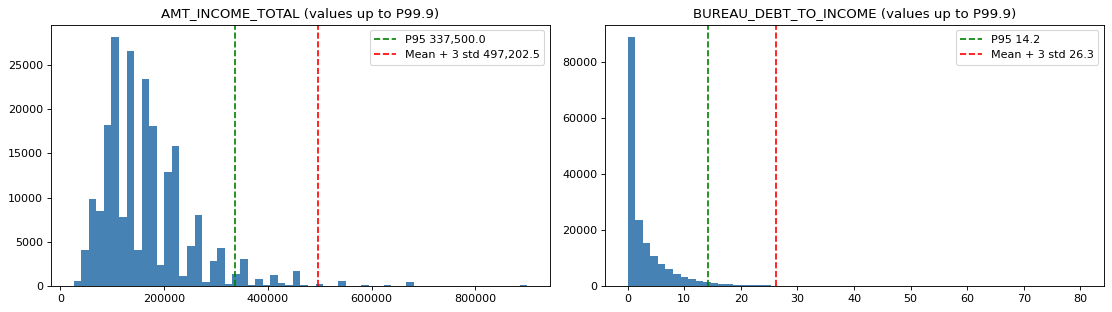

In [16]:
# the two most skewed characteristics: the 95th percentile (top fine bin starts here) and where a 3-std cap would sit
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['AMT_INCOME_TOTAL', 'BUREAU_DEBT_TO_INCOME']):
    s = apply_invalid_preview(col).dropna()
    ax.hist(s[s <= s.quantile(0.999)], bins=60, color='steelblue')
    ax.axvline(outlier_table.loc[col, 'P95'], color='green', linestyle='--', label=f"P95 {outlier_table.loc[col, 'P95']:,.1f}")
    ax.axvline(outlier_table.loc[col, 'Mean + 3 std'], color='red', linestyle='--', label=f"Mean + 3 std {outlier_table.loc[col, 'Mean + 3 std']:,.1f}")
    ax.set_title(f'{col} (values up to P99.9)')
    ax.legend()
plt.tight_layout()
plt.show()


**What we found**

- **Small effect.** About 19,400 values (0.01%-2.3% per characteristic) lie beyond +/-3 standard deviations. They are plausible (high earners, large loans, long tenure, heavily indebted applicants), not errors.
- **Capping would not change our scorecard.** For every characteristic the 3-std limits fall outside the 5th-95th percentile range, so the affected values are in the lowest or highest fine bin either way. Their bin, WOE and IV are the same with or without capping.
- **Very skewed amounts.** For `BUREAU_DEBT_TO_INCOME`, a few values up to 388 times income inflate the standard deviation, so a cap would sit at about 26 times income, far above the 95th percentile of about 14. Quantile binning handles this long tail directly.
- **Extreme applicants stay extreme.** With the raw values, an applicant with a very high debt burden stays in the highest-risk group, which is what we want.
- **Our decision:** no capping. We only treat the invalid values in 4.4.

## 4.6 Correlation and Redundancy Screening

In Week 9 Ex Q2 we flagged pairs with correlation above 0.8 or below -0.8 and dropped one of each pair. We use the same |r| > 0.8 threshold on all numeric predictors (continuous, discrete, date-relative). We check the 0/1 flags separately, and leave out text categories, because correlating category codes would be meaningless.

**How we differ from the lab.** In the lab we dropped the member of each pair with the weaker correlation to `BAD`. That uses `TARGET`, so it should only be done on training data. Here we settle each pair with **business and data-quality reasons** (formula relationship, interpretability, missingness), so we do not use `TARGET` at all. As the table shows, no pair is left that needs `TARGET` to decide.

In [17]:
numeric_predictors = [c for c in predictors if pd.api.types.is_numeric_dtype(merged_orig[c]) and merged_orig[c].nunique() > 2]
binary_predictors = [c for c in predictors if pd.api.types.is_numeric_dtype(merged_orig[c]) and merged_orig[c].nunique() == 2]

cor = merged_orig[numeric_predictors].corr()
binary_cor = merged_orig[binary_predictors].corr()

def high_pairs(matrix, threshold=0.8):
    upper = matrix.where(np.triu(np.ones(matrix.shape, dtype=bool), k=1)).stack()
    pairs = upper[upper.abs() > threshold].reset_index()
    pairs.columns = ['Feature A', 'Feature B', 'Correlation']
    return pairs.reindex(pairs['Correlation'].abs().sort_values(ascending=False).index).reset_index(drop=True)

pairs = pd.concat([high_pairs(cor), high_pairs(binary_cor)], ignore_index=True)

def relationship(a, b):
    stem = lambda c: c.rsplit('_', 1)[0] if c.endswith(('_AVG', '_MODE', '_MEDI')) else None
    if stem(a) and stem(a) == stem(b): return 'Same building measure (AVG / MODE / MEDI)'
    if a in building_cols and b in building_cols: return 'Related building measures'
    if {a, b} in ({'DAYS_BIRTH', 'AGE_YEARS'}, {'DAYS_EMPLOYED', 'EMPLOYMENT_YEARS'}): return 'Unit conversion'
    if 'FLAG_DAYS_EMPLOYED_SPECIAL' in (a, b) and 'FLAG_EMP_PHONE' in (a, b): return 'Exact inverse flags'
    if 'SOCIAL_CIRCLE' in a and 'SOCIAL_CIRCLE' in b: return 'Overlapping time windows'
    if a.startswith(('REG_', 'LIVE_')) and b.startswith(('REG_', 'LIVE_')): return 'Overlapping address-mismatch definitions'
    if a.startswith('REGION_RATING') and b.startswith('REGION_RATING'): return 'Same rating with / without city'
    if {a, b} == {'AMT_CREDIT', 'AMT_GOODS_PRICE'}: return 'Financial: loan usually equals goods price'
    if {a, b} == {'CNT_CHILDREN', 'CNT_FAM_MEMBERS'}: return 'Household size includes children'
    return 'Mathematical: one is calculated from the other or both share an input'

def pair_action(a, b):
    ra, rb = relevance.loc[a, 'Recommendation'], relevance.loc[b, 'Recommendation']
    if ra == 'KEEP' and rb == 'KEEP': return 'BOTH RETAINED: resolve on training data'
    if ra == 'KEEP': return f'Retain {a}, remove {b}'
    if rb == 'KEEP': return f'Retain {b}, remove {a}'
    return 'Both removed (other reasons, see 4.2)'

pairs['Relationship'] = [relationship(a, b) for a, b in zip(pairs['Feature A'], pairs['Feature B'])]
pairs['Proposed action'] = [pair_action(a, b) for a, b in zip(pairs['Feature A'], pairs['Feature B'])]
pairs['Justification'] = [relevance.loc[b if relevance.loc[a, 'Recommendation'] == 'KEEP' else a, 'Business justification']
                          for a, b in zip(pairs['Feature A'], pairs['Feature B'])]
pairs['Missing % A'] = merged_orig[pairs['Feature A']].isnull().mean().values * 100
pairs['Missing % B'] = merged_orig[pairs['Feature B']].isnull().mean().values * 100

building_pair = pairs['Relationship'].str.contains('building')
print(f'Pairs with |r| > 0.8: {len(pairs)} ({building_pair.sum()} between building variables, all proposed for removal)')
print(pairs['Proposed action'].str.split(':').str[0].str.replace(r'Retain .*', 'Retain one, remove the other', regex=True).value_counts().to_string())
with pd.option_context('display.float_format', '{:,.3f}'.format):
    display(pairs.loc[~building_pair, ['Feature A', 'Feature B', 'Correlation', 'Relationship', 'Proposed action', 'Justification', 'Missing % A', 'Missing % B']])

Pairs with |r| > 0.8: 121 (104 between building variables, all proposed for removal)
Proposed action
Both removed (other reasons, see 4.2)    113
Retain one, remove the other               8


,Feature A,Feature B,Correlation,Relationship,Proposed action,Justification,Missing % A,Missing % B
0,DAYS_EMPLOYED,EMPLOYMENT_YEARS,-1.000,Unit conversion,"Retain EMPLOYMENT_YEARS, remove DAYS_EMPLOYED","Same information as EMPLOYMENT_YEARS (r = -1.00) plus the 365243 code, which FLAG_DAYS_EMPLOYED_SPECIAL keeps",0.000,19.797
1,DAYS_BIRTH,AGE_YEARS,-1.000,Unit conversion,"Both removed (other reasons, see 4.2)",Same information as AGE_YEARS (r = -1.00); age not used as a characteristic (team decision),0.000,0.000
2,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.999,Overlapping time windows,"Both removed (other reasons, see 4.2)",Defaults among the applicant's social circle: judges the applicant by other people's behaviour,0.347,0.347
21,AMT_CREDIT,AMT_GOODS_PRICE,0.987,Financial: loan usually equals goods price,"Retain AMT_CREDIT, remove AMT_GOODS_PRICE",r = 0.99 with AMT_CREDIT; the difference is kept by CREDIT_TO_GOODS_RATIO,0.000,0.105
46,DAYS_EMPLOYED,EMPLOYMENT_AGE_RATIO,-0.956,Mathematical: one is calculated from the other or both share an input,"Both removed (other reasons, see 4.2)","Same information as EMPLOYMENT_YEARS (r = -1.00) plus the 365243 code, which FLAG_DAYS_EMPLOYED_SPECIAL keeps",0.000,19.797
47,EMPLOYMENT_YEARS,EMPLOYMENT_AGE_RATIO,0.956,Mathematical: one is calculated from the other or both share an input,"Retain EMPLOYMENT_YEARS, remove EMPLOYMENT_AGE_RATIO","r = 0.96 with EMPLOYMENT_YEARS, which is easier to interpret",19.797,19.797
48,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.951,Same rating with / without city,"Both removed (other reasons, see 4.2)",Team decision: the lender's region rating is not relevant to the applicant's repayment ability,0.000,0.000
49,BUREAU_DEBT_TO_INCOME,TOTAL_EXPOSURE_TO_INCOME,0.945,Mathematical: one is calculated from the other or both share an input,"Retain BUREAU_DEBT_TO_INCOME, remove TOTAL_EXPOSURE_TO_INCOME",r = 0.94 with BUREAU_DEBT_TO_INCOME; the new loan is already in LOAN_TO_INCOME,18.177,18.177
72,AMT_INCOME_TOTAL,INCOME_PER_FAMILY_MEMBER,0.888,Mathematical: one is calculated from the other or both share an input,"Retain AMT_INCOME_TOTAL, remove INCOME_PER_FAMILY_MEMBER",r = 0.89 with AMT_INCOME_TOTAL; also depends on family size (fairness proxy),0.000,0.001
76,CNT_CHILDREN,CNT_FAM_MEMBERS,0.880,Household size includes children,"Both removed (other reasons, see 4.2)",Proxy for family status,0.000,0.001


In [18]:
# building pairs summarised (all building variables are proposed for removal in 4.2)
pairs.loc[building_pair].groupby('Relationship').agg(Pairs=('Correlation', 'size'),
                                                      Min_abs_r=('Correlation', lambda s: s.abs().min()),
                                                      Max_abs_r=('Correlation', lambda s: s.abs().max()))

,Pairs,Min_abs_r,Max_abs_r
Relationship,,,
Related building measures,62,0.8061,0.9432
Same building measure (AVG / MODE / MEDI),42,0.9593,0.9985


In [19]:
# confirm that no pair of proposed candidates exceeds the threshold
candidate_cols = relevance.index[relevance['Recommendation'] == 'KEEP'].tolist()
candidate_numeric = [c for c in candidate_cols if c in numeric_predictors + binary_predictors]
candidate_pairs = high_pairs(merged_orig[candidate_numeric].corr())
print(f'Numeric candidates checked: {len(candidate_numeric)} | pairs with |r| > 0.8 among them: {len(candidate_pairs)}')

remaining = merged_orig[candidate_numeric].corr().where(np.triu(np.ones((len(candidate_numeric),) * 2, dtype=bool), k=1)).stack()
print('Highest remaining |r| among candidates:')
remaining.abs().sort_values(ascending=False).head(5).round(3).to_frame('|r|')

Numeric candidates checked: 23 | pairs with |r| > 0.8 among them: 0
Highest remaining |r| among candidates:


|r|
LOAN_TO_INCOME    ANNUITY_TO_INCOME        0.7920
ACTIVE_LOAN_COUNT ACTIVE_CREDIT_CARD_COUNT 0.7700
BUREAU_LOAN_COUNT ACTIVE_LOAN_COUNT        0.6910
AMT_CREDIT        CREDIT_TO_ANNUITY_RATIO  0.6670
                  LOAN_TO_INCOME           0.6600

**What we found**

- **121 pairs have |r| > 0.8.** 104 are between building variables: 42 AVG/MODE/MEDI duplicates (0.96-0.998) and 62 between related building measures (0.81-0.94). We drop all of these columns anyway.
- **The other 17 pairs are all explained by how the data was built:**
  - unit conversions (days vs years)
  - an exact inverse flag (`FLAG_EMP_PHONE` vs the special-employment flag)
  - formula relationships (a ratio vs its input)
  - overlapping definitions (30- vs 60-day windows, region rating with and without city, address-mismatch flags)
  - loan amount vs goods price
- **How we settled them.** In 10 pairs we keep one and drop the other, choosing the easier-to-explain or less-missing measure. In the other 7, both members are dropped for other reasons.
- **We did not use `TARGET`** for any pair, so we do not need the Week 9 weaker-correlation rule and no pair is left for the training data.
- **Check on our candidates.** No two candidates correlate above 0.8. The highest are `LOAN_TO_INCOME` / `ANNUITY_TO_INCOME` (0.79) and `ACTIVE_LOAN_COUNT` / `ACTIVE_CREDIT_CARD_COUNT` (0.77). Both are below the threshold and measure different things (loan size vs instalment burden; all credit vs revolving credit), so we keep both for IV screening.

## 4.7 Feature Engineering and Extraction Opportunities

Week 9 asked which variables would be more useful combined as a ratio or difference. We already built many of these in Steps 1 and 2, so we start with an inventory so we do not create them twice.

In [20]:
existing_features = pd.DataFrame([
    ('LOAN_TO_INCOME', 'AMT_CREDIT / AMT_INCOME_TOTAL', 'Step 2'),
    ('ANNUITY_TO_INCOME', 'AMT_ANNUITY / AMT_INCOME_TOTAL', 'Step 2'),
    ('CREDIT_TO_GOODS_RATIO', 'AMT_CREDIT / AMT_GOODS_PRICE', 'Step 2'),
    ('CREDIT_TO_ANNUITY_RATIO', 'AMT_CREDIT / AMT_ANNUITY', 'Step 2'),
    ('INCOME_PER_FAMILY_MEMBER', 'AMT_INCOME_TOTAL / CNT_FAM_MEMBERS', 'Step 2'),
    ('EMPLOYMENT_YEARS', '-DAYS_EMPLOYED / 365.25 (missing for 365243)', 'Step 2'),
    ('EMPLOYMENT_AGE_RATIO', 'EMPLOYMENT_YEARS / AGE_YEARS', 'Step 2'),
    ('BUREAU_DEBT_TO_INCOME', 'TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL', 'Step 2'),
    ('TOTAL_EXPOSURE_TO_INCOME', '(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL', 'Step 2'),
    ('AVG_DEBT_PER_ACTIVE_LOAN', 'TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT', 'Step 2'),
    ('EXISTING_DEBT_SHARE_OF_EXPOSURE', 'TOTAL_ACTIVE_DEBT / (TOTAL_ACTIVE_DEBT + AMT_CREDIT)', 'Step 2'),
    ('ACTIVE_LOAN_RATIO', 'ACTIVE_LOAN_COUNT / BUREAU_LOAN_COUNT', 'Step 1'),
    ('DEBT_TO_CREDIT_RATIO', 'TOTAL_ACTIVE_DEBT / TOTAL_ACTIVE_CREDIT', 'Step 1'),
], columns=['Existing characteristic', 'Formula', 'Created in'])
existing_features['Proposed status'] = [relevance.loc[c, 'Recommendation'] for c in existing_features['Existing characteristic']]
existing_features

,Existing characteristic,Formula,Created in,Proposed status
0,LOAN_TO_INCOME,AMT_CREDIT / AMT_INCOME_TOTAL,Step 2,KEEP
1,ANNUITY_TO_INCOME,AMT_ANNUITY / AMT_INCOME_TOTAL,Step 2,KEEP
2,CREDIT_TO_GOODS_RATIO,AMT_CREDIT / AMT_GOODS_PRICE,Step 2,KEEP
3,CREDIT_TO_ANNUITY_RATIO,AMT_CREDIT / AMT_ANNUITY,Step 2,KEEP
4,INCOME_PER_FAMILY_MEMBER,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,Step 2,DROP
5,EMPLOYMENT_YEARS,-DAYS_EMPLOYED / 365.25 (missing for 365243),Step 2,KEEP
6,EMPLOYMENT_AGE_RATIO,EMPLOYMENT_YEARS / AGE_YEARS,Step 2,DROP
7,BUREAU_DEBT_TO_INCOME,TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL,Step 2,KEEP
8,TOTAL_EXPOSURE_TO_INCOME,(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL,Step 2,DROP
9,AVG_DEBT_PER_ACTIVE_LOAN,TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT,Step 2,DROP


**Other features we considered.** We only add one: a 12-month enquiry total. The data dictionary says the six `AMT_REQ_CREDIT_BUREAU_*` windows **do not overlap** (for example, "one month before application, excluding one week before application"). So their sum is the total number of bureau enquiries in the 12 months before the application. That is a common credit-seeking measure, and it replaces six sparse columns, two of them more than 99% zero.

In [21]:
# preview only: the proposed enquiry total on a temporary series (not added to any DataFrame)
qrt_preview = apply_invalid_preview('AMT_REQ_CREDIT_BUREAU_QRT')
enquiry_total_preview = merged_orig[[c for c in enquiry_cols if c != 'AMT_REQ_CREDIT_BUREAU_QRT']].sum(axis=1, min_count=6 - 1) + qrt_preview
enquiry_total_preview[merged_orig[enquiry_cols].isnull().any(axis=1)] = np.nan

print('Preview of TOTAL_BUREAU_ENQUIRIES_12M (not created):')
print(enquiry_total_preview.describe().round(2).to_string())
print(f"Share of zero: {(enquiry_total_preview == 0).mean() * 100:.1f}% | max |r| with retained candidates: "
      f"{max(abs(enquiry_total_preview.corr(merged_orig[c])) for c in candidate_numeric):.3f}")

Preview of TOTAL_BUREAU_ENQUIRIES_12M (not created):
count   183,599.0000
mean          2.5700
std           2.2500
min           0.0000
25%           1.0000
50%           2.0000
75%           4.0000
max          31.0000
Share of zero: 15.0% | max |r| with retained candidates: 0.090


In [22]:
proposed_features = pd.DataFrame([
    ('TOTAL_BUREAU_ENQUIRIES_12M', 'All six AMT_REQ_CREDIT_BUREAU_* windows', 'HOUR + DAY + WEEK + MON + QRT + YEAR (missing if any window is missing)',
     'Credit-seeking intensity in the last 12 months, a standard bureau risk indicator; windows are exclusive so the sum is meaningful',
     'Replaces the six window columns (all proposed for removal)', 'RECOMMEND: create'),
    ('OVERDUE_LOAN_RATIO', 'OVERDUE_LOAN_COUNT, BUREAU_LOAN_COUNT', 'OVERDUE_LOAN_COUNT / BUREAU_LOAN_COUNT',
     'Delinquency frequency relative to the number of accounts',
     'Built in Step 1 and dropped as redundant with OVERDUE_LOAN_COUNT', 'Not recommended'),
    ('BUREAU_ANNUITY_TO_INCOME', 'Bureau AMT_ANNUITY, AMT_INCOME_TOTAL', 'TOTAL_ACTIVE_ANNUITY / AMT_INCOME_TOTAL',
     'Existing repayment obligations relative to income',
     'Input dropped in Step 1 (59% missing)', 'Not possible'),
    ('CREDIT_CARD_UTILISATION', 'Card debt, card limit', 'Active card debt / TOTAL_REVOLVING_LIMIT',
     'Revolving utilisation',
     'Card-level debt is not in the flattened data; overall utilisation already in DEBT_TO_CREDIT_RATIO', 'Not possible'),
    ('RESIDUAL_INCOME_PER_MEMBER', 'AMT_INCOME_TOTAL, AMT_ANNUITY, CNT_FAM_MEMBERS', '(income - annuity) / family members',
     'Disposable income per household member',
     'Annuity / income period not confirmed (Step 2); depends on family size (fairness proxy); close to ANNUITY_TO_INCOME', 'Not recommended'),
    ('PROPERTY_SIZE_INDEX', 'Building _AVG fields', 'Average of normalised size measures',
     'Property-related consolidation',
     'Describes the building where the applicant lives, 46.7-69.4% missing', 'Not recommended'),
    ('ANY_DELINQUENCY_FLAG', 'OVERDUE_LOAN_COUNT, ADVERSE_STATUS_COUNT', '1 if either > 0',
     'Simple delinquency indicator',
     'WOE grouping of the two counts (0 vs >= 1) already gives this', 'Not recommended'),
], columns=['Proposed new characteristic', 'Source columns', 'Formula', 'Business justification', 'Potential redundancy', 'Recommendation'])
proposed_features

,Proposed new characteristic,Source columns,Formula,Business justification,Potential redundancy,Recommendation
0,TOTAL_BUREAU_ENQUIRIES_12M,All six AMT_REQ_CREDIT_BUREAU_* windows,HOUR + DAY + WEEK + MON + QRT + YEAR (missing if any window is missing),"Credit-seeking intensity in the last 12 months, a standard bureau risk indicator; windows are exclusive so the sum is meaningful",Replaces the six window columns (all proposed for removal),RECOMMEND: create
1,OVERDUE_LOAN_RATIO,"OVERDUE_LOAN_COUNT, BUREAU_LOAN_COUNT",OVERDUE_LOAN_COUNT / BUREAU_LOAN_COUNT,Delinquency frequency relative to the number of accounts,Built in Step 1 and dropped as redundant with OVERDUE_LOAN_COUNT,Not recommended
2,BUREAU_ANNUITY_TO_INCOME,"Bureau AMT_ANNUITY, AMT_INCOME_TOTAL",TOTAL_ACTIVE_ANNUITY / AMT_INCOME_TOTAL,Existing repayment obligations relative to income,Input dropped in Step 1 (59% missing),Not possible
3,CREDIT_CARD_UTILISATION,"Card debt, card limit",Active card debt / TOTAL_REVOLVING_LIMIT,Revolving utilisation,Card-level debt is not in the flattened data; overall utilisation already in DEBT_TO_CREDIT_RATIO,Not possible
4,RESIDUAL_INCOME_PER_MEMBER,"AMT_INCOME_TOTAL, AMT_ANNUITY, CNT_FAM_MEMBERS",(income - annuity) / family members,Disposable income per household member,Annuity / income period not confirmed (Step 2); depends on family size (fairness proxy); close to ANNUITY_TO_INCOME,Not recommended
5,PROPERTY_SIZE_INDEX,Building _AVG fields,Average of normalised size measures,Property-related consolidation,"Describes the building where the applicant lives, 46.7-69.4% missing",Not recommended
6,ANY_DELINQUENCY_FLAG,"OVERDUE_LOAN_COUNT, ADVERSE_STATUS_COUNT",1 if either > 0,Simple delinquency indicator,WOE grouping of the two counts (0 vs >= 1) already gives this,Not recommended


**What we found**

- **Added.** We add one new characteristic: `TOTAL_BUREAU_ENQUIRIES_12M`.
  - The dictionary defines the six enquiry windows as non-overlapping, so their sum is a real 12-month count.
  - In the preview it has a median of 2, a maximum of 31 and only 15% zeros.
  - Its correlation with every candidate we keep is at most 0.09, so it adds new information.
  - It replaces six columns, two of which are more than 99% zero.
- **Not added:**
  - Two features are impossible because their inputs were removed in Step 1 or never existed.
  - One would recreate a feature we already dropped as redundant in Step 1.
  - The rest either repeat what WOE grouping will do anyway, or depend on the building data or the family-size proxy.

## 4.8 Characteristic Reduction

### Drop register

We list every characteristic we remove, grouped by main reason. The correlation evidence column shows its strongest correlation with any characteristic we keep (numeric only), which shows whether its information survives in what we keep.

In [23]:
candidate_set = set(candidate_cols)

def correlation_evidence(col):
    if col not in numeric_predictors + binary_predictors:
        return 'n/a (text)'
    others = [c for c in candidate_numeric if c != col]
    with np.errstate(divide='ignore', invalid='ignore'):
        r = merged_orig[others].corrwith(merged_orig[col])
    if r.abs().max() != r.abs().max():
        return 'n/a'
    best = r.abs().idxmax()
    return f'{r[best]:+.2f} with {best}'

drop_register = relevance[relevance['Recommendation'] == 'DROP'].copy()
drop_register['Correlation evidence'] = [correlation_evidence(c) for c in drop_register.index]
drop_register['Approval'] = 'Agreed'
drop_register = drop_register.reset_index().rename(columns={'Column': 'Characteristic'})
drop_register = drop_register.sort_values(['Primary reason', 'Characteristic']).reset_index(drop=True)
drop_register.index = drop_register.index + 1

print(drop_register['Primary reason'].value_counts().to_string())
print(f'Total proposed removals: {len(drop_register)}')
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(drop_register[['Characteristic', 'Proposed decision', 'Primary reason', 'Missing %', 'Correlation evidence', 'Business justification', 'Approval']])

Primary reason
High missingness                     50
Near-zero variance                   23
High redundancy                      22
Business irrelevance                 17
Fairness, availability or leakage    14
Invalid or unusable                   2
Total proposed removals: 128


,Characteristic,Proposed decision,Primary reason,Missing %,Correlation evidence,Business justification,Approval
1,AGE_YEARS,DROP,Business irrelevance,0.00,+0.62 with FLAG_DAYS_EMPLOYED_SPECIAL,Team decision: age eligibility (18+) is already enforced by the Step 0 segmentation; age is not used as a scoring characteristic,Agreed
2,CREDIT_TYPE_DIVERSITY,DROP,Business irrelevance,14.75,+0.49 with BUREAU_LOAN_COUNT,"Indirect bureau descriptors (mix of credit types, time since last closure, bureau reporting timing); risk content covered by retained co...",Agreed
3,DAYS_ID_PUBLISH,DROP,Business irrelevance,0.00,-0.29 with FLAG_DAYS_EMPLOYED_SPECIAL,"Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)",Agreed
4,DAYS_LAST_PHONE_CHANGE,DROP,Business irrelevance,0.00,-0.17 with OLDEST_CREDIT_AGE,"Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)",Agreed
5,DAYS_REGISTRATION,DROP,Business irrelevance,0.00,-0.21 with FLAG_DAYS_EMPLOYED_SPECIAL,"Timing of administrative changes (registration, ID document, phone); indirect at best, weak EDA signal (|r| <= 0.056)",Agreed
6,FLAG_DOCUMENT_3,DROP,Business irrelevance,0.00,-0.25 with FLAG_DAYS_EMPLOYED_SPECIAL,Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59),Agreed
7,FLAG_DOCUMENT_6,DROP,Business irrelevance,0.00,+0.59 with FLAG_DAYS_EMPLOYED_SPECIAL,Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59),Agreed
8,FLAG_DOCUMENT_8,DROP,Business irrelevance,0.00,-0.12 with FLAG_DAYS_EMPLOYED_SPECIAL,Undocumented document requirement set by the lending process; FLAG_DOCUMENT_6 also mirrors the pensioner flag (r = 0.59),Agreed
9,FLAG_EMAIL,DROP,Business irrelevance,0.00,-0.07 with FLAG_DAYS_EMPLOYED_SPECIAL,"Contactability, not repayment ability; administrative information",Agreed
10,FLAG_PHONE,DROP,Business irrelevance,0.00,-0.09 with CREDIT_TO_GOODS_RATIO,"Contactability, not repayment ability; administrative information",Agreed


### Retention list

In [24]:
def quality_concerns(col):
    notes = []
    pct = merged_orig[col].isnull().mean() * 100
    if pct > 0:
        notes.append(f'{pct:.1f}% missing')
    rule_ids = [r['id'] for r in invalid_rules if col in r['set_missing']]
    if rule_ids:
        notes.append(f"invalid rule {', '.join(rule_ids)}")
    if col in outlier_table.index and outlier_table.loc[col, 'Values beyond +/-3 std'] > 0:
        notes.append(f"long tail (~{int(outlier_table.loc[col, 'Values beyond +/-3 std']):,} values beyond 3 std, kept for binning)")
    if relevance.loc[col, 'Proposed decision'] == 'REVIEW':
        notes.append('REVIEW decision')
    return '; '.join(notes) or 'None'

retention = relevance.loc[candidate_cols, ['Business category', 'Primary reason', 'Business justification']].copy()
retention.columns = ['Business category', 'Risk dimension', 'Why retain?']

retention['Data-quality concerns'] = [quality_concerns(c) for c in retention.index]
retention['Later screening required?'] = 'Yes: WOE/IV on training data'
retention.loc['TOTAL_BUREAU_ENQUIRIES_12M (proposed new)'] = ['Credit history and recency', 'Credit history',
    'Credit-seeking intensity in the last 12 months (4.7)', f"{enquiry_total_preview.isnull().mean() * 100:.1f}% missing; new feature",
    'Yes: WOE/IV on training data']
retention.index.name = 'Characteristic'
retention = retention.sort_values('Risk dimension')
retention.index = [f'{i + 1}. {c}' for i, c in enumerate(retention.index)]

print(retention['Risk dimension'].value_counts().to_string())
print(f'\nEstimated post-reduction candidate count: {len(retention)} '
      f"({len(candidate_cols)} existing characteristics + {len(retention) - len(candidate_cols)} proposed new feature)")
retention

Risk dimension
Credit exposure         10
Affordability            6
Employment stability     5
Credit history           3
Delinquency              3
Housing and assets       2
Loan characteristics     1

Estimated post-reduction candidate count: 30 (29 existing characteristics + 1 proposed new feature)


,Business category,Risk dimension,Why retain?,Data-quality concerns,Later screening required?
1. AMT_INCOME_TOTAL,Income and affordability,Affordability,Primary measure of repayment capacity; directly reported by the applicant,"invalid rule R4; long tail (~1,868 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data
2. AMT_CREDIT,Loan characteristics,Affordability,Size of the exposure the lender takes on,"long tail (~2,533 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data
3. CREDIT_TO_ANNUITY_RATIO,Loan characteristics,Affordability,"Implied number of instalments, i.e. loan term; longer terms carry more uncertainty","0.0% missing; long tail (~14 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data
4. CREDIT_TO_GOODS_RATIO,Loan characteristics,Affordability,"Borrowing above the goods price (fees, insurance, extra cash); EDA showed a different profile for bads","0.1% missing; long tail (~1,788 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data
5. ANNUITY_TO_INCOME,Income and affordability,Affordability,"Instalment burden relative to income (same-period relative index, Step 2)","0.0% missing; invalid rule R4, R5; long tail (~2,667 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data
6. LOAN_TO_INCOME,Income and affordability,Affordability,Loan size relative to income: standard leverage measure,"invalid rule R4; long tail (~3,229 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data
7. ACTIVE_LOAN_COUNT,Historical credit exposure,Credit exposure,Number of current obligations; steady bad-rate gradient in EDA,14.8% missing,Yes: WOE/IV on training data
8. EXISTING_DEBT_SHARE_OF_EXPOSURE,Historical credit exposure,Credit exposure,How much of the total post-loan exposure is existing debt,18.2% missing,Yes: WOE/IV on training data
9. MICROLOAN_COUNT,Historical credit exposure,Credit exposure,Short-term high-cost credit; one microloan had an 18.6% bad rate (EDA),14.8% missing,Yes: WOE/IV on training data
10. DEBT_TO_CREDIT_RATIO,Historical credit exposure,Credit exposure,Utilisation of existing credit,"34.3% missing; invalid rule R6; long tail (~255 values beyond 3 std, kept for binning)",Yes: WOE/IV on training data


**What we found**

- **Reduction.** Our candidate set goes from **157 to 30**: 29 existing characteristics plus 1 new feature. That is within our 20-35 target.
- **Each characteristic we keep has its own clear risk meaning:**
  - existing credit exposure (10)
  - affordability (6)
  - job stability (5)
  - arrears (3)
  - credit history (3, including the enquiry total)
  - housing and assets (2)
  - loan type (1)
- **No two of them correlate above 0.8**, so cutting more now would throw away information before we know how predictive it is. That is the job of IV screening on the training data in Step 5, which should remove the weakest of these 30 (for example the near-constant `TOTAL_PROLONGATIONS` or `MORTGAGE_COUNT`).

## 4.9 Summary of Our Decisions

A short summary of every decision before we apply anything to the data.

### A. Removals (by main reason)

In [25]:
removals = (drop_register.groupby('Primary reason')['Characteristic']
            .agg(Count='size', Characteristics=lambda s: ', '.join(s)))
removals.loc['Total'] = [removals['Count'].sum(), '']
removals

,Count,Characteristics
Primary reason,,
Business irrelevance,17,"AGE_YEARS, CREDIT_TYPE_DIVERSITY, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE, DAYS_REGISTRATION, FLAG_DOCUMENT_3, FLAG_DOCUMENT_6, FLAG_DOC..."
"Fairness, availability or leakage",14,"CNT_CHILDREN, CODE_GENDER, DEF_30_CNT_SOCIAL_CIRCLE, DEF_60_CNT_SOCIAL_CIRCLE, LIVE_CITY_NOT_WORK_CITY, LIVE_REGION_NOT_WORK_REGION, NAM..."
High missingness,50,"APARTMENTS_AVG, APARTMENTS_MEDI, APARTMENTS_MODE, BASEMENTAREA_AVG, BASEMENTAREA_MEDI, BASEMENTAREA_MODE, COMMONAREA_AVG, COMMONAREA_MED..."
High redundancy,22,"ACTIVE_CONSUMER_CREDIT_COUNT, ACTIVE_LOANS_PER_INCOME, AMT_ANNUITY, AMT_GOODS_PRICE, AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_QR..."
Invalid or unusable,2,"MAX_REMAINING_DURATION, ORGANIZATION_TYPE"
Near-zero variance,23,"AMT_REQ_CREDIT_BUREAU_DAY, AMT_REQ_CREDIT_BUREAU_HOUR, FLAG_CONT_MOBILE, FLAG_DOCUMENT_10, FLAG_DOCUMENT_11, FLAG_DOCUMENT_12, FLAG_DOCU..."
Total,128,


### B. More than 40% missing

In [26]:
over40[['Missing %', 'Recommendation']].assign(Decision='Pending').style.format({'Missing %': '{:.1f}'})

,Missing %,Recommendation,Decision
Characteristic,,,
COMMONAREA_AVG,69.4,DROP,Pending
COMMONAREA_MODE,69.4,DROP,Pending
COMMONAREA_MEDI,69.4,DROP,Pending
NONLIVINGAPARTMENTS_AVG,69.0,DROP,Pending
NONLIVINGAPARTMENTS_MODE,69.0,DROP,Pending
NONLIVINGAPARTMENTS_MEDI,69.0,DROP,Pending
FONDKAPREMONT_MODE,67.9,DROP,Pending
LIVINGAPARTMENTS_AVG,67.9,DROP,Pending
LIVINGAPARTMENTS_MEDI,67.9,DROP,Pending


### C. Invalid-value rules

In [27]:
invalid_table[['Characteristic', 'Invalid-value rule', 'Invalid count', 'Proposed treatment', 'Judgement call']]

,Characteristic,Invalid-value rule,Invalid count,Proposed treatment,Judgement call
Rule,,,,,
R1,DAYS_EMPLOYED,DAYS_EMPLOYED == 365243,42230,Set to NaN: DAYS_EMPLOYED,No
R2,CODE_GENDER,CODE_GENDER == 'XNA',4,Set to NaN: CODE_GENDER,No
R3,ORGANIZATION_TYPE,ORGANIZATION_TYPE == 'XNA',42230,Set to NaN: ORGANIZATION_TYPE,No
R4,AMT_INCOME_TOTAL (+ income-based ratios),"AMT_INCOME_TOTAL > 20,000,000",1,"Set to NaN: AMT_INCOME_TOTAL, LOAN_TO_INCOME, ANNUITY_TO_INCOME, INCOME_PER_FAMILY_MEMBER, BUREAU_DEBT_TO_INCOME, TOTAL_EXPOSURE_TO_INCO...",Yes
R5,ANNUITY_TO_INCOME,ANNUITY_TO_INCOME > 1,23,Set to NaN: ANNUITY_TO_INCOME,Yes
R6,DEBT_TO_CREDIT_RATIO,DEBT_TO_CREDIT_RATIO > 10,4,Set to NaN: DEBT_TO_CREDIT_RATIO,Yes
R7,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_QRT > 30,1,Set to NaN: AMT_REQ_CREDIT_BUREAU_QRT,Yes
R8,OWN_CAR_AGE,OWN_CAR_AGE > 50,2482,Set to NaN: OWN_CAR_AGE,Yes


### D. Feature engineering

| New characteristic | Formula | Why |
|---|---|---|
| `TOTAL_BUREAU_ENQUIRIES_12M` | Sum of the six non-overlapping `AMT_REQ_CREDIT_BUREAU_*` windows; missing if any window is missing | How actively the applicant looked for credit in the last 12 months; replaces six sparse columns |

We add no other new characteristic (4.7).

### E. Final candidates and summary

In [28]:
print('Proposed final candidates:')
print(', '.join(c.split('. ', 1)[1] for c in retention.index))

reason_counts = drop_register['Primary reason'].value_counts()
business_drops = reason_counts.get('Business irrelevance', 0) + reason_counts.get('Fairness, availability or leakage', 0)
summary_table = pd.DataFrame({'Result': [
    len(predictors),
    business_drops,
    reason_counts.get('High missingness', 0),
    reason_counts.get('High redundancy', 0),
    reason_counts.get('Invalid or unusable', 0) + reason_counts.get('Near-zero variance', 0),
    1,
    len(predictors) - len(drop_register) + 1,
]}, index=['Initial predictor characteristics',
           'Proposed business-knowledge drops (incl. fairness)',
           'Proposed missingness drops',
           'Proposed redundancy drops',
           'Proposed other drops (invalid / unusable, near-zero variance)',
           'Additional features proposed',
           'Expected final candidate characteristics'])
assert summary_table.iloc[1:5, 0].sum() == len(drop_register), 'removal counts do not add up'
summary_table

Proposed final candidates:
AMT_INCOME_TOTAL, AMT_CREDIT, CREDIT_TO_ANNUITY_RATIO, CREDIT_TO_GOODS_RATIO, ANNUITY_TO_INCOME, LOAN_TO_INCOME, ACTIVE_LOAN_COUNT, EXISTING_DEBT_SHARE_OF_EXPOSURE, MICROLOAN_COUNT, DEBT_TO_CREDIT_RATIO, ACTIVE_LOAN_RATIO, MORTGAGE_COUNT, ACTIVE_CREDIT_CARD_COUNT, BUREAU_LOAN_COUNT, BUREAU_DEBT_TO_INCOME, HAS_BUREAU_HISTORY, OLDEST_CREDIT_AGE, MOST_RECENT_CREDIT_AGE, TOTAL_BUREAU_ENQUIRIES_12M (proposed new), TOTAL_PROLONGATIONS, ADVERSE_STATUS_COUNT, OVERDUE_LOAN_COUNT, FLAG_DAYS_EMPLOYED_SPECIAL, EMPLOYMENT_YEARS, OCCUPATION_TYPE, NAME_EDUCATION_TYPE, NAME_INCOME_TYPE, NAME_HOUSING_TYPE, FLAG_OWN_CAR, NAME_CONTRACT_TYPE


,Result
Initial predictor characteristics,157
Proposed business-knowledge drops (incl. fairness),31
Proposed missingness drops,50
Proposed redundancy drops,22
"Proposed other drops (invalid / unusable, near-zero variance)",25
Additional features proposed,1
Expected final candidate characteristics,30


### Decision checklist

**This is the end of Part A.** We went through these points as a team and **agreed them on 2026-10-30** (with the later changes listed in the next section):

1. **Drop list (A):** every characteristic marked for removal, including the REVIEW items we recommended dropping (`ORGANIZATION_TYPE`, `AMT_REQ_CREDIT_BUREAU_MON`, `AMT_REQ_CREDIT_BUREAU_YEAR`).
2. **More than 40% missing (B):** drop the 47 building variables, `OWN_CAR_AGE`, `EXT_SOURCE_1` and `MAX_HIST_OVERDUE`.
3. **Invalid-value rules (C):** R1-R3 (codes), plus the judgement calls R4-R8.
4. **Valid outliers (4.5):** kept as they are; no capping, because binning groups the tails.
5. **Missing values (4.3):** genuine missing values stay missing (WOE missing bin); only values removed by an invalid-value rule get the median of the valid values.
6. **New feature (D):** `TOTAL_BUREAU_ENQUIRIES_12M`.
7. **Final candidate list (E).** `AGE_YEARS`, `EXT_SOURCE_1`, `REGION_RATING_CLIENT` and `MAX_HIST_OVERDUE` removed.

## Configuration: our agreed decisions

We agreed the Part A decisions as a team on **2026-10-30**, and made these changes later:

- `EXT_SOURCE_1`, `AGE_YEARS` and `REGION_RATING_CLIENT` removed.
- `MAX_HIST_OVERDUE` removed (2026-11-06): 40.6% missing, above the 40% limit we apply to every other characteristic.
- No Z-score capping of valid outliers (2026-11-07): the caps sit above the 95th percentile, so they would not change any fine bin or WOE.
- Genuine missing values stay missing; only values removed by an invalid-value rule get a median.
- **No train/test split here.** We make the split in Step 5 (grouping and WOE/IV screening).

Part B only reads this configuration. We write out the columns we keep explicitly, so the preparation can be repeated, and check them against Part A.

In [29]:
APPROVED = True
APPROVAL_DATE = '2026-10-30'

APPROVED_CONFIG = {
    'keep_columns': [
        # affordability and loan
        'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_ANNUITY_RATIO',
        'CREDIT_TO_GOODS_RATIO', 'NAME_CONTRACT_TYPE',
        # employment and stability
        'EMPLOYMENT_YEARS', 'FLAG_DAYS_EMPLOYED_SPECIAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE',
        # housing and assets
        'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR',
        # existing credit exposure
        'HAS_BUREAU_HISTORY', 'BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ACTIVE_LOAN_RATIO', 'ACTIVE_CREDIT_CARD_COUNT',
        'BUREAU_DEBT_TO_INCOME', 'DEBT_TO_CREDIT_RATIO', 'EXISTING_DEBT_SHARE_OF_EXPOSURE', 'MORTGAGE_COUNT', 'MICROLOAN_COUNT',
        # delinquency
        'ADVERSE_STATUS_COUNT', 'OVERDUE_LOAN_COUNT', 'TOTAL_PROLONGATIONS',
        # credit history
        'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE',
    ],
    'invalid_rules': ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8'],
    'invalid_value_treatment': 'median of the valid values',
    'genuine_missing_treatment': 'kept as missing (no imputation)',
    'valid_outlier_treatment': 'kept as they are (no capping); grouped by binning in the next step',
    'new_features': {'TOTAL_BUREAU_ENQUIRIES_12M': enquiry_cols},
    'train_test_split': 'made in Step 5',
}

# the agreed configuration must match the Part A analysis exactly
approved_drop = [c for c in predictors if c not in APPROVED_CONFIG['keep_columns']]
assert set(APPROVED_CONFIG['keep_columns']) == set(candidate_cols), 'keep list differs from Part A'
assert set(approved_drop) == set(drop_register['Characteristic']), 'drop list differs from Part A'
print(f"Agreed on {APPROVAL_DATE}: keep {len(APPROVED_CONFIG['keep_columns'])} characteristics, "
      f"drop {len(approved_drop)}, {len(APPROVED_CONFIG['invalid_rules'])} invalid rules, "
      f"no capping, create {len(APPROVED_CONFIG['new_features'])} new feature")

Agreed on 2026-10-30: keep 29 characteristics, drop 128, 8 invalid rules, no capping, create 1 new feature


## 4.10 Apply Our Data Preparation

We apply our decisions in this order:

1. Make a working copy (`prepared`). `merged_orig` is never changed.
2. Apply the invalid-value rules: the value becomes `NaN` and we record where. No rows are removed.
3. Replace **only** those recorded invalid values with the median of the valid values.
4. Create `TOTAL_BUREAU_ENQUIRIES_12M`.
5. Keep only the columns we agreed on.
6. Check and export.

We do not cap valid outliers (4.5).

**About the split.** We make the train/test split in Step 5, so the medians here use all 213,312 applicants. They do not use `TARGET`, they are fixed, and we save them to a parameters file so they are never re-estimated. All `TARGET`-based work (binning, WOE/IV, characteristic selection) happens on the training sample in Step 5.

### Part B, step 1 - Working copy

In [30]:
if not APPROVED:
    raise RuntimeError('Part B requires APPROVED = True in the configuration')

work_cols = [id_col, target_col] + APPROVED_CONFIG['keep_columns'] + list(APPROVED_CONFIG['new_features']['TOTAL_BUREAU_ENQUIRIES_12M'])
prepared = merged_orig[work_cols].copy()
print(f'Working copy: {prepared.shape[0]:,} rows x {prepared.shape[1]} columns '
      f'(ID, TARGET, {len(APPROVED_CONFIG["keep_columns"])} retained characteristics, 6 enquiry inputs for the new feature)')

Working copy: 213,312 rows x 37 columns (ID, TARGET, 29 retained characteristics, 6 enquiry inputs for the new feature)


### Part B, step 2 - Invalid values to `NaN`

We check the rules on the original values. Rules on columns we dropped (R1-R3, R8) have no effect on the prepared data, and we report them that way.

In [31]:
rules_by_id = {r['id']: r for r in invalid_rules}
invalid_masks = {}
invalid_log = []

for rule_id in APPROVED_CONFIG['invalid_rules']:
    r = rules_by_id[rule_id]
    flagged = r['condition'](merged_orig).fillna(False).to_numpy()
    applied = [c for c in r['set_missing'] if c in prepared.columns]
    values_set = 0
    for col in applied:
        mask = flagged & prepared[col].notnull().to_numpy()
        prepared.loc[mask, col] = np.nan
        invalid_masks[col] = invalid_masks.get(col, np.zeros(len(prepared), dtype=bool)) | mask
        values_set += mask.sum()
    invalid_log.append({'Rule': rule_id, 'Rule text': r['rule'], 'Applicants flagged': int(flagged.sum()),
                        'Columns updated': ', '.join(applied) if applied else 'none (column dropped)',
                        'Values set to NaN': int(values_set)})

invalid_log = pd.DataFrame(invalid_log).set_index('Rule')
invalid_log

,Rule text,Applicants flagged,Columns updated,Values set to NaN
Rule,,,,
R1,DAYS_EMPLOYED == 365243,42230,none (column dropped),0
R2,CODE_GENDER == 'XNA',4,none (column dropped),0
R3,ORGANIZATION_TYPE == 'XNA',42230,none (column dropped),0
R4,"AMT_INCOME_TOTAL > 20,000,000",1,"AMT_INCOME_TOTAL, LOAN_TO_INCOME, ANNUITY_TO_INCOME, BUREAU_DEBT_TO_INCOME",4
R5,ANNUITY_TO_INCOME > 1,23,ANNUITY_TO_INCOME,23
R6,DEBT_TO_CREDIT_RATIO > 10,4,DEBT_TO_CREDIT_RATIO,4
R7,AMT_REQ_CREDIT_BUREAU_QRT > 30,1,AMT_REQ_CREDIT_BUREAU_QRT,1
R8,OWN_CAR_AGE > 50,2482,none (column dropped),0


### Part B, step 3 - Median for the invalid values only

We replace each recorded invalid value with the median of that characteristic's valid values. Genuine missing values in the same columns stay missing.

In [32]:
median_values = {}
median_log = []
for col, mask in invalid_masks.items():
    median_values[col] = prepared[col].median()
    prepared.loc[mask, col] = median_values[col]
    median_log.append({'Characteristic': col, 'Invalid values replaced': int(mask.sum()), 'Median used': median_values[col],
                       'Genuine missing kept': int(prepared[col].isnull().sum()),
                       'Genuine missing in source': int(merged_orig[col].isnull().sum())})
median_log = pd.DataFrame(median_log).set_index('Characteristic')
with pd.option_context('display.float_format', '{:,.4f}'.format):
    display(median_log)

,Invalid values replaced,Median used,Genuine missing kept,Genuine missing in source
Characteristic,,,,
AMT_INCOME_TOTAL,1,"148,500.0000",0,0
LOAN_TO_INCOME,1,3.1600,0,0
ANNUITY_TO_INCOME,24,0.1618,3,3
BUREAU_DEBT_TO_INCOME,1,1.2618,38773,38773
DEBT_TO_CREDIT_RATIO,4,0.6096,73159,73159
AMT_REQ_CREDIT_BUREAU_QRT,1,0.0000,29712,29712


### Part B, step 4 - New feature: `TOTAL_BUREAU_ENQUIRIES_12M`

The six enquiry windows do not overlap (data dictionary), so their sum is the number of bureau enquiries in the 12 months before the application. The total is missing when the windows are missing (they are always missing together, for applicants without bureau history). We then remove the six input columns.

In [33]:
inputs = APPROVED_CONFIG['new_features']['TOTAL_BUREAU_ENQUIRIES_12M']
prepared['TOTAL_BUREAU_ENQUIRIES_12M'] = prepared[inputs].sum(axis=1, min_count=len(inputs))
prepared = prepared.drop(columns=inputs)

print(prepared['TOTAL_BUREAU_ENQUIRIES_12M'].describe().round(2).to_string())
print(f"Missing: {prepared['TOTAL_BUREAU_ENQUIRIES_12M'].isnull().sum():,}")

count   183,600.0000
mean          2.5700
std           2.2500
min           0.0000
25%           1.0000
50%           2.0000
75%           4.0000
max          31.0000
Missing: 29,712


### Part B, step 5 - Final columns and integrity checks

In [34]:
final_predictors = APPROVED_CONFIG['keep_columns'] + list(APPROVED_CONFIG['new_features'])
prepared = prepared[[id_col, target_col] + final_predictors]

numeric_final = [c for c in final_predictors if pd.api.types.is_numeric_dtype(prepared[c])]
final_cor = prepared[numeric_final].corr()
final_high_pairs = high_pairs(final_cor)

remaining_invalid = sum(int(r['condition'](prepared).fillna(False).sum())
                        for r in invalid_rules if all(c in prepared.columns for c in r['set_missing'][:1]))

checks = {
    'Same number of applicants (no rows removed)': len(prepared) == len(merged_orig),
    'Same applicants in the same order': prepared[id_col].equals(merged_orig[id_col]),
    'SK_ID_CURR unique': prepared[id_col].is_unique,
    'TARGET unchanged': prepared[target_col].equals(merged_orig[target_col]),
    f'{len(final_predictors)} predictors + ID + TARGET': prepared.shape[1] == len(final_predictors) + 2,
    'No invalid values remain (our rules re-checked)': remaining_invalid == 0,
    'Genuine missing values unchanged (retained columns)': all(prepared[c].isnull().sum() == merged_orig[c].isnull().sum()
                                                                for c in APPROVED_CONFIG['keep_columns']),
    'Valid values unchanged (no capping)': all(prepared[c][~invalid_masks[c]].equals(merged_orig[c][~invalid_masks[c]]) if c in invalid_masks
                                               else prepared[c].equals(merged_orig[c]) for c in APPROVED_CONFIG['keep_columns']),
    'No infinite values': not np.isinf(prepared[numeric_final]).any().any(),
    'No predictor pair with |r| > 0.8': len(final_high_pairs) == 0,
    'Source data unchanged (fingerprint)': pd.util.hash_pandas_object(merged_orig, index=True).sum() == original_fingerprint,
}
integrity = pd.DataFrame({'Passed': checks})
display(integrity)
if not integrity['Passed'].all():
    raise AssertionError('Integrity check failed: ' + ', '.join(integrity.index[~integrity['Passed']]))
print(f'Prepared data: {prepared.shape[0]:,} rows x {prepared.shape[1]} columns')

,Passed
Same number of applicants (no rows removed),True
Same applicants in the same order,True
SK_ID_CURR unique,True
TARGET unchanged,True
30 predictors + ID + TARGET,True
No invalid values remain (our rules re-checked),True
Genuine missing values unchanged (retained columns),True
Valid values unchanged (no capping),True
No infinite values,True
No predictor pair with |r| > 0.8,True


Prepared data: 213,312 rows x 32 columns


### Part B, step 6 - Export

We save two files in `data/`:

- `prepared_data.csv`: one row per applicant with `SK_ID_CURR`, `TARGET` and the 30 prepared characteristics
- `prepared_data_parameters.json`: our decisions and every fitted value (medians, rules), so later steps can repeat exactly the same preparation without re-estimating anything

In [35]:
import json

output_path = 'data/prepared_data.csv'
params_path = 'data/prepared_data_parameters.json'
prepared.to_csv(output_path, index=False)

parameters = {
    'approval_date': APPROVAL_DATE,
    'source_file': merged_path,
    'rows': int(len(prepared)),
    'predictors': final_predictors,
    'dropped_columns': {reason: group['Characteristic'].tolist() for reason, group in drop_register.groupby('Primary reason')},
    'invalid_rules': {r: rules_by_id[r]['rule'] + ' -> NaN in ' + ', '.join(rules_by_id[r]['set_missing']) for r in APPROVED_CONFIG['invalid_rules']},
    'invalid_value_medians': {c: float(v) for c, v in median_values.items()},
    'valid_outlier_treatment': APPROVED_CONFIG['valid_outlier_treatment'],
    'new_features': {'TOTAL_BUREAU_ENQUIRIES_12M': ' + '.join(inputs) + ' (missing if any window is missing)'},
    'genuine_missing_treatment': APPROVED_CONFIG['genuine_missing_treatment'],
    'fitted_on': 'all applicants (train/test split made in Step 5); no TARGET information used',
}
with open(params_path, 'w') as f:
    json.dump(parameters, f, indent=2)

# confirm the export by reloading
reloaded = pd.read_csv(output_path)
print(f'Saved {output_path}: {reloaded.shape[0]:,} rows x {reloaded.shape[1]} columns, '
      f'{os.path.getsize(output_path) / 1e6:.1f} MB')
print(f'Saved {params_path}')
print('Reloaded file matches:', reloaded.shape == prepared.shape and reloaded[id_col].equals(prepared[id_col]))
del reloaded

Saved data/prepared_data.csv: 213,312 rows x 32 columns, 59.7 MB
Saved data/prepared_data_parameters.json
Reloaded file matches: True


## 4.11 Final Data Preparation Summary

In [36]:
predictors_before = merged_orig[predictors]
# invalid values in the source: every (rule, column) combination, retained or dropped
invalid_before = sum(int((rules_by_id[r]['condition'](merged_orig).fillna(False) & merged_orig[c].notnull()).sum())
                     for r in APPROVED_CONFIG['invalid_rules'] for c in rules_by_id[r]['set_missing'])

before_after = pd.DataFrame({
    'Before preparation': [f'{len(merged_orig):,}', len(predictors), f'{predictors_before.isnull().sum().sum():,}',
                           f'{invalid_before:,}', 0, len(pairs)],
    'After preparation': [f'{len(prepared):,}', len(final_predictors), f'{prepared[final_predictors].isnull().sum().sum():,}',
                          remaining_invalid, 0, len(final_high_pairs)],
}, index=['Rows', 'Predictor columns', 'Missing values (predictor cells)', 'Invalid observations',
          'Capped observations', 'High-correlation feature pairs (|r| > 0.8)'])
before_after

,Before preparation,After preparation
Rows,"213,312","213,312"
Predictor columns,157,30
Missing values (predictor cells),"7,491,844","638,769"
Invalid observations,"86,981",0
Capped observations,0,0
High-correlation feature pairs (|r| > 0.8),121,0


In [37]:
# characteristics dropped, by reason
display(removals)

# high-correlation characteristics removed (one member of each retained pair)
display(pairs.loc[pairs['Proposed action'].str.startswith('Retain'), ['Feature A', 'Feature B', 'Correlation', 'Proposed action']]
        .reset_index(drop=True))

# missing values in the prepared data (kept as missing for the WOE missing bin)
prepared_missing = prepared[final_predictors].isnull().mean().mul(100).round(2)
prepared_missing[prepared_missing > 0].sort_values(ascending=False).to_frame('Missing % (kept as missing)')

,Count,Characteristics
Primary reason,,
Business irrelevance,17,"AGE_YEARS, CREDIT_TYPE_DIVERSITY, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE, DAYS_REGISTRATION, FLAG_DOCUMENT_3, FLAG_DOCUMENT_6, FLAG_DOC..."
"Fairness, availability or leakage",14,"CNT_CHILDREN, CODE_GENDER, DEF_30_CNT_SOCIAL_CIRCLE, DEF_60_CNT_SOCIAL_CIRCLE, LIVE_CITY_NOT_WORK_CITY, LIVE_REGION_NOT_WORK_REGION, NAM..."
High missingness,50,"APARTMENTS_AVG, APARTMENTS_MEDI, APARTMENTS_MODE, BASEMENTAREA_AVG, BASEMENTAREA_MEDI, BASEMENTAREA_MODE, COMMONAREA_AVG, COMMONAREA_MED..."
High redundancy,22,"ACTIVE_CONSUMER_CREDIT_COUNT, ACTIVE_LOANS_PER_INCOME, AMT_ANNUITY, AMT_GOODS_PRICE, AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_QR..."
Invalid or unusable,2,"MAX_REMAINING_DURATION, ORGANIZATION_TYPE"
Near-zero variance,23,"AMT_REQ_CREDIT_BUREAU_DAY, AMT_REQ_CREDIT_BUREAU_HOUR, FLAG_CONT_MOBILE, FLAG_DOCUMENT_10, FLAG_DOCUMENT_11, FLAG_DOCUMENT_12, FLAG_DOCU..."
Total,128,


,Feature A,Feature B,Correlation,Proposed action
0,DAYS_EMPLOYED,EMPLOYMENT_YEARS,-1.0000,"Retain EMPLOYMENT_YEARS, remove DAYS_EMPLOYED"
1,AMT_CREDIT,AMT_GOODS_PRICE,0.9868,"Retain AMT_CREDIT, remove AMT_GOODS_PRICE"
2,EMPLOYMENT_YEARS,EMPLOYMENT_AGE_RATIO,0.9563,"Retain EMPLOYMENT_YEARS, remove EMPLOYMENT_AGE_RATIO"
3,BUREAU_DEBT_TO_INCOME,TOTAL_EXPOSURE_TO_INCOME,0.9447,"Retain BUREAU_DEBT_TO_INCOME, remove TOTAL_EXPOSURE_TO_INCOME"
4,AMT_INCOME_TOTAL,INCOME_PER_FAMILY_MEMBER,0.8880,"Retain AMT_INCOME_TOTAL, remove INCOME_PER_FAMILY_MEMBER"
5,OLDEST_CREDIT_AGE,CREDIT_HISTORY_AGE_RATIO,0.8517,"Retain OLDEST_CREDIT_AGE, remove CREDIT_HISTORY_AGE_RATIO"
6,TOTAL_ACTIVE_DEBT,BUREAU_DEBT_TO_INCOME,0.8373,"Retain BUREAU_DEBT_TO_INCOME, remove TOTAL_ACTIVE_DEBT"
7,FLAG_EMP_PHONE,FLAG_DAYS_EMPLOYED_SPECIAL,-0.9999,"Retain FLAG_DAYS_EMPLOYED_SPECIAL, remove FLAG_EMP_PHONE"


,Missing % (kept as missing)
DEBT_TO_CREDIT_RATIO,34.3000
OCCUPATION_TYPE,32.6800
EMPLOYMENT_YEARS,19.8000
BUREAU_DEBT_TO_INCOME,18.1800
EXISTING_DEBT_SHARE_OF_EXPOSURE,18.1800
MORTGAGE_COUNT,14.7500
ACTIVE_LOAN_RATIO,14.7500
ACTIVE_LOAN_COUNT,14.7500
BUREAU_LOAN_COUNT,14.7500
ACTIVE_CREDIT_CARD_COUNT,14.7500


In [38]:
n_bureau_missing = (~has_bureau).sum()
summary_text = f'''
**Summary of our data preparation**

- **Applicants:** {len(merged_orig):,} before and {len(prepared):,} after. We removed no applicant, and the bad rate stays at {prepared[target_col].mean() * 100:.2f}%.
- **Predictors:** {len(predictors)} reduced to {len(final_predictors)}.
  - {len(drop_register)} characteristics dropped: {', '.join(f"{n} {r.lower()}" for r, n in removals['Count'].drop('Total').items())}.
  - 1 new characteristic: `TOTAL_BUREAU_ENQUIRIES_12M`, the sum of the six non-overlapping enquiry windows.
- **Invalid values:** {int(invalid_log['Values set to NaN'].sum()):,} values in the columns we kept broke our invalid-value rules. We replaced them with the median of the valid values ({', '.join(f"`{c}` {int(n)}" for c, n in median_log['Invalid values replaced'].items())}). Rules R1-R3 and R8 only affect columns we dropped.
- **Missing values:** we did **not** fill genuine missing values. They remain in {(prepared_missing > 0).sum()} characteristics: mainly the {n_bureau_missing:,} applicants without bureau history, plus unreported or undefined bureau values, and the {prepared['OCCUPATION_TYPE'].isnull().sum():,} applicants without an occupation. They will get their own WOE bin.
- **Outliers:** we kept valid extreme values as they are (no capping). The quantile bins in Step 5 put them in the lowest or highest bin.
- **Redundancy:** no pair of prepared characteristics correlates above 0.8 (before: {len(pairs)} pairs).

**Data-quality limitations we still have**

- **Pooled missing values.** For bureau characteristics, one missing bin combines "no bureau history", "no active loan" and "not reported". `DEBT_TO_CREDIT_RATIO` is {prepared_missing['DEBT_TO_CREDIT_RATIO']:.1f}% missing and `BUREAU_DEBT_TO_INCOME` {prepared_missing['BUREAU_DEBT_TO_INCOME']:.1f}%.
- **Long tails.** The heavily skewed amounts keep their long tails. For example, `BUREAU_DEBT_TO_INCOME` reaches {prepared['BUREAU_DEBT_TO_INCOME'].max():,.0f} times income against a median of {prepared['BUREAU_DEBT_TO_INCOME'].median():.1f}. So we need quantile-based binning.
- **Bureau window.** `OLDEST_CREDIT_AGE` is limited by the roughly 8-year bureau window.
- **Annuity units.** The income/annuity period is not confirmed, so `ANNUITY_TO_INCOME` is a relative index.
- **Fitting sample.** We estimated the invalid-value medians on all applicants because the split is made in Step 5. They do not use `TARGET`, and in Step 5 we fit all binning and WOE on the training sample only.
- **Small categories.** Some categories (for example in `NAME_INCOME_TYPE`) are small, so we will merge them during coarse classing.

**Why our data is ready for grouping and WOE/IV screening**

Every characteristic we kept has a clear link to repayment ability, belongs to one of the core credit-risk dimensions we covered in class, has no known invalid values or special codes, and does not repeat another one. We keep missing values on purpose so we can measure their risk, and quantile binning will group the extreme values. In Step 5 we split the data, group each characteristic and screen it with WOE/IV.
'''
display(Markdown(summary_text))


**Summary of our data preparation**

- **Applicants:** 213,312 before and 213,312 after. We removed no applicant, and the bad rate stays at 7.96%.
- **Predictors:** 157 reduced to 30.
  - 128 characteristics dropped: 17 business irrelevance, 14 fairness, availability or leakage, 50 high missingness, 22 high redundancy, 2 invalid or unusable, 23 near-zero variance.
  - 1 new characteristic: `TOTAL_BUREAU_ENQUIRIES_12M`, the sum of the six non-overlapping enquiry windows.
- **Invalid values:** 32 values in the columns we kept broke our invalid-value rules. We replaced them with the median of the valid values (`AMT_INCOME_TOTAL` 1, `LOAN_TO_INCOME` 1, `ANNUITY_TO_INCOME` 24, `BUREAU_DEBT_TO_INCOME` 1, `DEBT_TO_CREDIT_RATIO` 4, `AMT_REQ_CREDIT_BUREAU_QRT` 1). Rules R1-R3 and R8 only affect columns we dropped.
- **Missing values:** we did **not** fill genuine missing values. They remain in 18 characteristics: mainly the 31,471 applicants without bureau history, plus unreported or undefined bureau values, and the 69,712 applicants without an occupation. They will get their own WOE bin.
- **Outliers:** we kept valid extreme values as they are (no capping). The quantile bins in Step 5 put them in the lowest or highest bin.
- **Redundancy:** no pair of prepared characteristics correlates above 0.8 (before: 121 pairs).

**Data-quality limitations we still have**

- **Pooled missing values.** For bureau characteristics, one missing bin combines "no bureau history", "no active loan" and "not reported". `DEBT_TO_CREDIT_RATIO` is 34.3% missing and `BUREAU_DEBT_TO_INCOME` 18.2%.
- **Long tails.** The heavily skewed amounts keep their long tails. For example, `BUREAU_DEBT_TO_INCOME` reaches 388 times income against a median of 1.3. So we need quantile-based binning.
- **Bureau window.** `OLDEST_CREDIT_AGE` is limited by the roughly 8-year bureau window.
- **Annuity units.** The income/annuity period is not confirmed, so `ANNUITY_TO_INCOME` is a relative index.
- **Fitting sample.** We estimated the invalid-value medians on all applicants because the split is made in Step 5. They do not use `TARGET`, and in Step 5 we fit all binning and WOE on the training sample only.
- **Small categories.** Some categories (for example in `NAME_INCOME_TYPE`) are small, so we will merge them during coarse classing.

**Why our data is ready for grouping and WOE/IV screening**

Every characteristic we kept has a clear link to repayment ability, belongs to one of the core credit-risk dimensions we covered in class, has no known invalid values or special codes, and does not repeat another one. We keep missing values on purpose so we can measure their risk, and quantile binning will group the extreme values. In Step 5 we split the data, group each characteristic and screen it with WOE/IV.
